# DES Y3 cosmic shear: data vectors from the compiled CosmoLike interface

This notebook computes the cosmic-shear predictions of the DES Y3 project with
`cosmolike_des_y3_interface`, the project's *compiled interface*: C and C++ code
built into a Python module (through the pybind11 library), imported below as
`ci`. It shows

- the shear angular power spectra $C_\ell^{EE}$ and the real-space correlation
  functions $\xi_\pm(\theta)$ of the four source-galaxy redshift bins;
- how $\Omega_m$, $n_s$, the angular binning, baryonic feedback and the numerical
  accuracy settings change them;
- the $\chi^2=(d-t)^{\mathsf T}C^{-1}(d-t)$ of the model against the DES Y3
  measurements, with $d$ the measured data vector, $t$ the prediction and $C$
  the published DES Y3 covariance matrix (the joint scatter of the measurements).

**Vocabulary.**

- A *tomographic bin* is one redshift slice of a galaxy sample. DES Y3 has four
  *source* bins, galaxies whose shapes measure the gravitational shear, and five
  redMaGiC *lens* bins, galaxies used as density tracers (they appear in
  EXAMPLE_EVALUATE2.ipynb). Redshifts come from broad-band colors (*photo-z*).
- The multipole $\ell$ is an angular frequency, roughly $180^\circ/\theta$;
  $C_\ell$ is the angular power spectrum at that frequency.
- The *data vector* is the ordered list of all measured two-point values. The
  DES Y3 3×2pt vector has 900 entries: 20 angular bins for each of the 10
  source-bin pairs of $\xi_+$ and of $\xi_-$, then galaxy–galaxy lensing and
  clustering. Its baseline *mask*, one 0/1 flag per entry, keeps 533 entries,
  227 of them $\xi_\pm$ entries.
- A *wrapper* is a Python function of this notebook that runs CAMB, hands the
  result and the nuisance parameters to `ci`, and returns NumPy arrays.

**Conventions.**

- Angles $\theta$ are in arcminutes throughout.
- `ci` returns plain, dimensionless $C_\ell$, without the factor
  $\ell(\ell+1)/2\pi$. The shear-spectrum plotter multiplies by that factor in
  its absolute panels; the $\xi$ plotter draws $\theta\,\xi_\pm\times10^4$.
- Arrays count tomographic bins from 0, panel labels count from 1: the panel
  labeled $(1,2)$ draws the array slice `[:, 0, 1]`.

**Running.** Follow the [notebook steps of the project README](README.md#notebooks)
(activate Cocoa, set `OMP_NUM_THREADS`, start Jupyter) and run the cells in
order. Every wrapper call runs CAMB once, so a sweep of ten values costs ten
CAMB runs.

## Setup: packages, threads and figure style

The first cell imports the packages and sets the figure style; the second adds
CAMB and the shared package `cosmolike_notebook_utils` (imported as `cnu`) to
`sys.path`, the list of folders Python searches for modules, and prints which
copies were found.

- `OMP_NUM_THREADS` sets how many OpenMP threads (parallel workers inside the
  compiled code) CosmoLike uses. An OpenMP runtime reads it once, when it
  starts, so the README sets it in the shell before Jupyter starts; the cell
  sets it again before `ci` is imported.
- `text.usetex = True` typesets all figure text with LaTeX and needs a LaTeX
  installation; set it to `False` if the figures fail to render.
- `IniFile` (from GetDist) reads `key = value` text files such as the project's
  `.dataset` file.

In [1]:
# Figures appear below each cell; 'retina' draws them at double resolution.
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import sys, platform, os
# OpenMP threads (parallel workers) of the compiled CosmoLike loops. The
# OpenMP runtime reads this variable once, when it starts, so it is set
# before ci is imported; the README sets it in the shell before Jupyter.
os.environ['OMP_NUM_THREADS'] = '4'
import matplotlib
import math
from matplotlib import pyplot as plt
import numpy as np
# EuclidEmulator2: used only when non_linear_emul = 1
import euclidemu2
import scipy
# ci: the project's compiled CosmoLike module
import cosmolike_des_y3_interface as ci
# IniFile reads key = value text files such as the .dataset file
from getdist import IniFile
import itertools
import iminuit
import functools
print(sys.version)
print(os.getcwd())

# GENERAL PLOT OPTIONS
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
# usetex typesets all figure text with LaTeX: it needs a LaTeX installation
matplotlib.rcParams['text.usetex'] = True

# Jupyter Notebook Display options
import IPython
IPython.display.display(IPython.display.HTML("<style>:root { --jp-notebook-max-width: 85% !important; }</style>"))
IPython.display.display(IPython.display.HTML("<style>div.output_scroll { height: 54em; }</style>"))


Classy could not be found in your system.
Here are some suggestions:

	 -Download the Class from class-code.net and install it
	  together with its wrapper classy (type 'make' instead of
	  'make class'
	 -If you know that Class is installed on your system
	  and yet classy could not be installed, try re-compiling
	  Class with just ''make'' instead of ''make class''
NOTICE: Even without classy you can still use EuclidEmulator2
        to emulate boost factors. You won't be able to compute
        full power spectra, though.


3.11.12 | packaged by conda-forge | (main, Apr 10 2025, 22:18:52) [Clang 18.1.8 ]
/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_y3


In [2]:
# IMPORT CAMB
# This build folder exists only on Linux x86_64. Python skips a missing
# folder in sys.path, so camb may come from another entry; the print shows
# which copy was imported.
sys.path.insert(0, os.environ['ROOTDIR']+'/external_modules/code/CAMB/build/lib.linux-x86_64-'+os.environ['PYTHON_VERSION'])
import camb
from camb import model
print('Using CAMB %s installed at %s'%(camb.__version__,os.path.dirname(camb.__file__)))

# IMPORT SHARED NOTEBOOK UTILITIES (cosmolike_core)
# cnu: the CAMB helper and plotting functions shared by every project
sys.path.insert(0, os.environ['ROOTDIR']+'/external_modules/code/cosmolike_core')
import cosmolike_notebook_utils as cnu
print('Using cosmolike_notebook_utils installed at %s'%(os.path.dirname(cnu.__file__)))


Using CAMB 1.6.7 installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/.local/lib/python3.11/site-packages/camb
Using cosmolike_notebook_utils installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/cosmolike_core/cosmolike_notebook_utils


## Run settings

These module-level variables (names defined at the top level of the notebook)
mirror keys of the likelihood YAML files, `likelihood/cosmic_shear.yaml` and
`EXAMPLE_EVALUATE1.yaml`:

| Variable | Meaning |
| --- | --- |
| `non_linear_emul` | Nonlinear matter power: 1 = EuclidEmulator2, 2 = CAMB Halofit (Takahashi version). |
| `CLprobe` | Probe combination of the $\chi^2$ section; `"xi"` is cosmic shear alone. |
| `path`, `data_file` | The DES Y3 dataset file; `path` is relative to this notebook's folder. |
| `IA_model` | Intrinsic-alignment model: 0 = NLA, 1 = TATT. |
| `IA_redshift_evolution` | 3 = each IA amplitude follows a power law in $(1+z)/1.62$. |
| `IA_code` | 0 = the C implementation of FAST-PT, the algorithm for the perturbation-theory integrals of TATT. |
| `photoz_interpolation_type`, `photoz_zmid_convention` | How the $n(z)$ tables are interpolated, and whether their redshift column holds left bin edges or bin centers. |
| `internal_accuracyboost` | FAST-PT internal grid, as a fraction of its output table. |
| `ntheta`, `theta_min_arcmin`, `theta_max_arcmin` | 20 logarithmic angular bins from 2.5 to 250 arcmin, as in the dataset. |

*Intrinsic alignment* (IA) is the correlation of galaxy shapes with the local
tidal field; it adds to the lensing signal and must be modeled. NLA, the
nonlinear linear-alignment model, has one amplitude $A_1$; TATT (tidal alignment
and tidal torquing) adds a quadratic amplitude $A_2$ and $b_{TA}$, which weights
the alignment by the source-galaxy density.

`CAMBAccuracyBoost` is not read by the wrappers below; each wrapper has its own
`CAMBAccuracyBoost = 1.1` default argument.

In [3]:
# Not read by the wrappers below: each has its own CAMBAccuracyBoost default
CAMBAccuracyBoost = 1.1
# Nonlinear power: 1 = EuclidEmulator2, 2 = CAMB Halofit (Takahashi)
non_linear_emul = 2
# Probe combination of the chi^2 section: xi = cosmic shear alone
CLprobe="xi"

# Relative to this notebook's folder; start_cocoa.sh links
# external_modules/data/des_y3 to this project's data folder.
path= "../../external_modules/data/des_y3"
data_file="des_y3_real.dataset"

# IA_model: 0 = NLA, 1 = TATT. IA_redshift_evolution = 3: power law in
# (1+z)/1.62, so A1 = [amplitude, exponent, ...] and likewise A2.
IA_model = 1
IA_redshift_evolution = 3
IA_code = 0  # 0 = C FASTPT, 1 = Python FAST-PT (NLA always uses 0)

# n(z) photo-z conventions (mirror the likelihood yaml keys):
# interpolation 0 = cspline, 1 = linear, 2+ = Steffen monotone;
# z column 0 = Z_LOW (left bin edges), 1 = Z_MID (sample points)
photoz_interpolation_type = 0
photoz_zmid_convention = 0

# C FAST-PT grid of the TATT and nonlinear-bias tables, as a fraction
# of its output table (mirrors the likelihood yaml key
# internal_accuracyboost, 1.0 in likelihood/*.yaml; the C default,
# used when nothing sets it, is 0.5)
internal_accuracyboost = 1.0

# 20 logarithmic angular bins from 2.5 to 250 arcmin, as in the dataset
ntheta = 20 
theta_min_arcmin = 2.5 
theta_max_arcmin = 250 

## Fiducial parameters

The default values of the wrapper arguments:

- Cosmology: `As_1e9` $=10^9A_s$, the primordial amplitude; `ns` $=n_s$; `H0` in
  km/s/Mpc; `omegab` $=\Omega_b$; `omegam` $=\Omega_m$, all matter including
  massive neutrinos; `mnu` $=\sum m_\nu$ in eV; `w` $=w_0$ and `w0pwa` $=w_0+w_a$,
  so $w_a=0$ here.
- Source photo-z shifts `DES_DZ_S1..4`: each source $n(z)$ is shifted in
  redshift by $\Delta z_i$.
- Shear calibration `DES_M1..4`: the measured shear of bin $i$ is $1+m_i$ times
  the true shear.
- TATT with power-law evolution: `DES_A1_1`, `DES_A1_2` are $A_1$ at $1+z=1.62$
  and its exponent $\eta_1$; `DES_A2_1`, `DES_A2_2` the same pair for $A_2$;
  `DES_BTA_1` is $b_{TA}$.

These are the values of the `sampler: evaluate: override` block of
`EXAMPLE_EVALUATE1.yaml`, except `DES_A2_1`, which that file sets to 0.01.

In [4]:
# Cosmology: As_1e9 = 10^9 A_s, H0 in km/s/Mpc, mnu = sum of neutrino
# masses in eV; w0pwa = w0 + wa (below), so wa = w0pwa - w = 0.
As_1e9 = 2.1
ns = 0.96605
H0 = 67.32
omegab = 0.04
omegam = 0.3
mnu = 0.06
# Source bins 1-4: photo-z shifts Delta z_i and shear calibration m_i
DES_DZ_S1 = 0.0414632
DES_DZ_S2 = 0.00147332
DES_DZ_S3 = 0.0237035
DES_DZ_S4 = -0.0773436
DES_M1 = 0.0191832
DES_M2 = -0.0431752
DES_M3 = -0.034961
DES_M4 = -0.0158096
# TATT: (A1, eta1) = (DES_A1_1, DES_A1_2), (A2, eta2) = (DES_A2_1,
# DES_A2_2), b_TA = DES_BTA_1. EXAMPLE_EVALUATE1.yaml sets DES_A2_1 = 0.01.
DES_A1_1 = 0.606102
DES_A1_2 = -1.51541
DES_A2_1 = -1.7938938475734911 
DES_A2_2 = -1.5448080290038528
DES_BTA_1 = 0.8154011496506723
w0pwa = -0.9
w = -0.9

## Stage 1, CAMB: matter power spectrum, growth and distances

Each wrapper starts with one CAMB run through `cnu.get_camb_cosmology`, shared by
every Cocoa project; `help(cnu.get_camb_cosmology)` prints its documentation.
It returns the ten arrays that `ci.set_cosmology` reads, in CosmoLike's units:

| Returned names | Content |
| --- | --- |
| `log10k_interp_2D`, `z_interp_2D` | The grids of $\log_{10}k$, with $k$ in $h$/Mpc, and of redshift of the power-spectrum tables. |
| `lnPL`, `lnPNL` | $\ln P(k,z)$, linear and nonlinear, with $P$ in (Mpc/$h$)$^3$, each table flattened into one array. |
| `G_growth`, `z_growth` | $G(z)=D(z)(1+z)$, with $D$ the linear growth factor, normalized at the last redshift of the 2D grid, on its own redshift grid. |
| `z_interp_1D`, `chi` | The comoving distance $\chi(z)$ in Mpc/$h$. |
| `omegan2`, `lnPL_cb` | $\Omega_\nu h^2$ and the linear power of cold dark matter plus baryons, read by halo-model quantities; the wrappers pass `omegan2` only. |

*Flattened* means the 2D table $(z,k)$ is stored as one 1D array, column after
column (Fortran order), the memory layout the compiled code expects.

Two knobs reach CAMB: it runs with accuracy
`CAMBAccuracyBoost`$\times(1+(\texttt{AccuracyBoost}-1)/3)$, and the redshift and
wavenumber grids grow with `CLAccuracyBoost`$\times$`AccuracyBoost`.

In [5]:
# get_camb_cosmology is shared by every project's notebooks; call it as
# cnu.get_camb_cosmology (imported above). The CAMB side runs with
# CAMBAccuracyBoost*(1 + (AccuracyBoost - 1)/3); kmax, k_per_logint, the
# chi(z) node count and lens_potential_accuracy grow with that CAMB boost;
# the EuclidEmulator2 boost (non_linear_emul = 1) applies only at z < 10.
# help(cnu.get_camb_cosmology) prints the full documentation.


## Stages 2 to 5: the harmonic-space wrapper `C_ss_tomo_limber`

After CAMB, each call runs four more stages:

2. **Accuracy of the C code.** `init_ntable_lmax` sets the largest multipole of
   the spectra tabulated for real-space transforms (50,000 at boost 1);
   `init_accuracy_boost` sets the size of CosmoLike's interpolation tables and
   the *quadrature level*, which picks how many points evaluate each
   line-of-sight integral; `init_photoz_conventions` sets how the $n(z)$ tables
   are read. The level passed is
   `CLIntegrationAccuracy` $+\,|3(\text{boost}-1)|$, rounded down, with
   boost $=$ `CLAccuracyBoost`$\times$`AccuracyBoost`: any boost different from
   1, above or below, raises it.
3. **`ci.set_cosmology`** copies the CAMB tables into CosmoLike, which reads them
   in every later calculation.
4. **Nuisance setters.** `set_nuisance_shear_calib` receives the four $m_i$,
   `set_nuisance_shear_photoz` the four $\Delta z_i$ and `set_nuisance_ia` the IA
   lists. With `IA_redshift_evolution = 3` only the first two entries of `A1` and
   of `A2` (amplitude, exponent) and the first entry of `B_TA` are read; the
   trailing zeros make each list as long as the number of source bins, which the
   setter requires. `reset_bary_struct` switches baryonic feedback off;
   `init_baryons_contamination` switches it on (see the baryon section).
5. **The data-vector call** `ci.C_ss_tomo_limber(l=ell)` returns a pair
   `(EE, BB)` of arrays with shape `[n_ell, n_source, n_source]`. Only the
   entries `[:, i, j]` with $i\le j$ are filled; the others are zero. The values
   are plain, dimensionless $C_\ell$ in the *Limber approximation*, which
   evaluates the matter power at $k=(\ell+1/2)/\chi$ along the line of sight
   instead of integrating over all wavenumbers; it loses accuracy only at the
   lowest multipoles.

The E mode is the curl-free pattern of the shear field, the pattern lensing
produces; in this model a B mode (curl pattern) comes only from the TATT terms.

**Python detail.** The default values in the `def` line (`omegam = omegam`, ...)
are copied once, when the cell runs: rerun the cell after editing the fiducial
values. Names that are not arguments (`mnu`, `non_linear_emul`, the photo-z
conventions and `ini`) are read from the notebook at every call; `ini` is created
by the initialization cell further below, which must run before the first call.

In [6]:
def C_ss_tomo_limber(ell, 
                     omegam = omegam, 
                     omegab = omegab, 
                     H0 = H0, 
                     ns = ns, 
                     As_1e9 = As_1e9, 
                     w = w, 
                     w0pwa = w0pwa,
                     A1  = [DES_A1_1, DES_A1_2, 0, 0], 
                     A2  = [DES_A2_1, DES_A2_2, 0, 0],
                     BTA = [DES_BTA_1, 0, 0, 0],
                     shear_photoz_bias = [DES_DZ_S1, DES_DZ_S2, DES_DZ_S3, DES_DZ_S4],
                     M = [DES_M1, DES_M2, DES_M3, DES_M4],
                     baryon_sims = None,
                     AccuracyBoost = 1.0, 
                     kmax = 10, 
                     k_per_logint = 20, 
                     CAMBAccuracyBoost=1.1,
                     CLAccuracyBoost = 1.0, 
                     CLIntegrationAccuracy = 1):

    # Stage 1, CAMB: the ten arrays of the CAMB section (lnPL_cb is not used)
    (log10k_interp_2D, z_interp_2D, lnPL, lnPNL, G_growth, z_growth, z_interp_1D, chi,
     omegan2, lnPL_cb) = cnu.get_camb_cosmology(omegam=omegam, 
        omegab=omegab, H0=H0, ns=ns, As_1e9=As_1e9, w=w, w0pwa=w0pwa, mnu=mnu, non_linear_emul=non_linear_emul,
            AccuracyBoost=AccuracyBoost, kmax=kmax,
        k_per_logint=k_per_logint, CAMBAccuracyBoost=CAMBAccuracyBoost,
        CLAccuracyBoost=CLAccuracyBoost)

    # Stage 2, accuracy of the C code. The quadrature level grows by 3 per
    # unit of |boost - 1|, so a boost below 1 raises it too.
    CLAccuracyBoost = CLAccuracyBoost * AccuracyBoost
    CLIntegrationAccuracy = max(0, CLIntegrationAccuracy + abs(3*(CLAccuracyBoost-1.0)))
    ci.init_ntable_lmax(int(50000 + 20000*(CLAccuracyBoost-1)))
    ci.init_accuracy_boost(CLAccuracyBoost, int(CLIntegrationAccuracy))
    ci.init_photoz_conventions(
        int(photoz_interpolation_type),
        int(photoz_zmid_convention))

    # Stage 3: copy the CAMB tables into CosmoLike
    ci.set_cosmology(omegam = omegam, 
                     H0 = H0, 
                     log10k_2D = log10k_interp_2D, 
                     z_2D = z_interp_2D, 
                     lnP_linear = lnPL,
                     lnP_nonlinear = lnPNL,
                     G = G_growth,
                     z_G = z_growth,
                     z_1D = z_interp_1D,
                     chi = chi,
                     omegan2 = omegan2)
    # Stage 4, nuisance parameters. With IA_redshift_evolution = 3 the IA
    # setter reads A1[0:2], A2[0:2] and BTA[0]; the zeros pad each list to
    # the number of source bins, which the setter requires.
    ci.set_nuisance_shear_calib(M = M)
    ci.set_nuisance_shear_photoz(bias = shear_photoz_bias)
    ci.set_nuisance_ia(A1 = A1, A2 = A2, B_TA = BTA)

    # Baryonic feedback off (dark-matter-only power), or the tabulated power
    # ratio of the named simulation; ini comes from the initialization cell.
    if baryon_sims is None:
        ci.reset_bary_struct()
    else:
        ci.init_baryons_contamination(sim = baryon_sims,
            allsims = ini.relativeFileName('all_sims_hdf5_file'))
        
    # Stage 5: the pair (EE, BB), each [n_ell, n_source, n_source] with only
    # [:, i, j], i <= j, filled: plain dimensionless Limber C_ell
    return ci.C_ss_tomo_limber(l = ell)

## The real-space wrapper `xi`

`xi(...)` runs the same stages and adds `ci.init_binning(ntheta, theta_min,
theta_max)`, which defines `ntheta` logarithmic angular bins between the two
angles in arcmin. `ci.xi_pm_tomo()` transforms the tabulated $C_\ell$, up to the
`init_ntable_lmax` multipole, into $\xi_+$ and $\xi_-$ averaged over each angular
bin rather than evaluated at its center.

The wrapper returns the tuple `(theta, xi_plus, xi_minus)`: `theta` holds the
area-weighted centers of the angular bins in arcmin
(`ci.get_binning_real_space()`), and each $\xi$ array has the shape
`[n_theta, n_source, n_source]`, symmetric in the two bin indices. This tuple is
the input format of `cnu.plot_xi`.

In [7]:
def xi(ntheta = ntheta, 
       theta_min_arcmin = theta_min_arcmin, 
       theta_max_arcmin = theta_max_arcmin, 
       omegam = omegam, 
       omegab = omegab, 
       H0 = H0, 
       ns = ns, 
       As_1e9 = As_1e9, 
       w = w, 
       w0pwa = w0pwa,
       A1  = [DES_A1_1, DES_A1_2, 0.0, 0.0], 
       A2  = [DES_A2_1, DES_A2_2, 0.0, 0.0],
       BTA = [DES_BTA_1, 0, 0, 0.0, 0.0],     
       shear_photoz_bias = [DES_DZ_S1, DES_DZ_S2, DES_DZ_S3, DES_DZ_S4],
       M = [DES_M1, DES_M2, DES_M3, DES_M4],
       baryon_sims = None,
       AccuracyBoost = 1.0, 
       kmax = 10, 
       k_per_logint = 20, 
       CAMBAccuracyBoost=1.1,
       CLAccuracyBoost = 1.0, 
       CLIntegrationAccuracy = 1):

    # Stage 1, CAMB
    (log10k_interp_2D, z_interp_2D, lnPL, lnPNL, G_growth, z_growth, z_interp_1D, chi,
     omegan2, lnPL_cb) = cnu.get_camb_cosmology(omegam=omegam, 
        omegab=omegab, H0=H0, ns=ns, As_1e9=As_1e9, w=w, w0pwa=w0pwa, mnu=mnu, non_linear_emul=non_linear_emul,
            AccuracyBoost=AccuracyBoost, kmax=kmax,
        k_per_logint=k_per_logint, CAMBAccuracyBoost=CAMBAccuracyBoost,
        CLAccuracyBoost=CLAccuracyBoost)

    # Stage 2, accuracy of the C code, as in C_ss_tomo_limber
    CLAccuracyBoost = CLAccuracyBoost * AccuracyBoost
    CLIntegrationAccuracy = max(0, CLIntegrationAccuracy + abs(3*(CLAccuracyBoost-1.0)))
    ci.init_ntable_lmax(int(50000 + 20000*(CLAccuracyBoost-1)))
    ci.init_accuracy_boost(CLAccuracyBoost, int(CLIntegrationAccuracy))
    ci.init_photoz_conventions(
        int(photoz_interpolation_type),
        int(photoz_zmid_convention))
    
    # ntheta logarithmic bins in arcmin (int: the binding accepts only a
    # Python int). A new binning gets a new cache key: kernels are rebuilt.
    ci.init_binning(int(ntheta), theta_min_arcmin, theta_max_arcmin)
    
    # Stage 3: copy the CAMB tables into CosmoLike
    ci.set_cosmology(omegam = omegam, 
                     H0 = H0, 
                     log10k_2D = log10k_interp_2D, 
                     z_2D = z_interp_2D, 
                     lnP_linear = lnPL,
                     lnP_nonlinear = lnPNL,
                     G = G_growth,
                     z_G = z_growth,
                     z_1D = z_interp_1D,
                     chi = chi,
                     omegan2 = omegan2)
    # Stage 4: nuisance parameters and baryons, as in C_ss_tomo_limber
    ci.set_nuisance_shear_calib(M = M)
    ci.set_nuisance_shear_photoz(bias = shear_photoz_bias)
    ci.set_nuisance_ia(A1 = A1, A2 = A2, B_TA = BTA)

    if baryon_sims is None:
        ci.reset_bary_struct()
    else:
        ci.init_baryons_contamination(sim = baryon_sims,
            allsims = ini.relativeFileName('all_sims_hdf5_file'))
        
    # Stage 5: bin-averaged xi_+ and xi_-, each [n_theta, n_source, n_source]
    (xip, xim) = ci.xi_pm_tomo()    
    # Bin centers in arcmin first: the tuple cnu.plot_xi expects
    return (ci.get_binning_real_space(), xip, xim)

## The shared plotting functions

`cnu.plot_C_ss_tomo_limber` and `cnu.plot_xi` draw one panel per source-bin pair
$(i,j)$ in a lower triangle, in one of two modes:

- **Absolute**, without a reference argument: each panel has its own y range;
  the spectra appear as $\ell(\ell+1)C_\ell/2\pi$ on a logarithmic axis, the
  correlation functions as $\theta\,\xi_\pm\times10^4$ on a linear axis.
  `ylim = [a, b]` multiplies each panel's minimum by $a$ and its maximum by $b$.
- **Reference**, with `C_ss_ref=` or `xi_ref=`: each panel shows the fractional
  difference value/reference $-\,1$ on one shared linear band. `ylim` is then
  written around 1: `ylim = (0.96, 1.04)` draws the band from $-0.04$ to $+0.04$.

A list `param` of swept values colors the curves and the colorbar; `legend` names
the curves instead. `help(cnu.plot_xi)` lists every option.

In [8]:
# plot_C_ss_tomo_limber is shared by every project; call it as
# cnu.plot_C_ss_tomo_limber (imported above). help(cnu.plot_C_ss_tomo_limber)
# prints every argument; the markdown above explains the two modes.


In [9]:
# plot_xi is shared by every project; call it as cnu.plot_xi (imported
# above). help(cnu.plot_xi) prints every argument; the markdown above
# explains the two modes.


## Initialize CosmoLike once

The next cell configures the compiled module before the first wrapper call;
the wrappers then change only cosmology, nuisance parameters and accuracy.

- `ini` reads `des_y3_real.dataset`; `relativeFileName(key)` returns the file
  named under `key`, with the dataset's folder prepended.
- `initial_setup` resets every CosmoLike setting to its default.
- `init_fpt_internal_boost` comes before the first `init_accuracy_boost` call,
  because that call scales the value it finds then.
- `init_cosmo_runmode(is_linear=False)` selects the nonlinear matter power.
- `init_redshift_distributions_from_files` reads the lens and source $n(z)$
  tables: a redshift column, then one column per tomographic bin.
- `init_IA` selects the IA model, its redshift evolution and the FAST-PT code.

The `int(...)` conversions are needed because several bindings accept only a
Python integer, not a float or a NumPy integer.

In [10]:
# Init Cosmolike
# relativeFileName(key) returns the file named under key in the dataset
# file, with the dataset's folder prepended
ini = IniFile(os.path.normpath(os.path.join(path, data_file)))

lens_file = ini.relativeFileName('nz_lens_file')
source_file = ini.relativeFileName('nz_source_file')
lens_ntomo = ini.int("lens_ntomo")
source_ntomo = ini.int("source_ntomo")

# Reset every CosmoLike setting to its default value
ci.initial_setup()

# set before the first init_accuracy_boost, as the likelihood does:
# init_accuracy_boost scales this fraction from the value it finds at
# its first call in the process
ci.init_fpt_internal_boost(internal_boost = float(internal_accuracyboost))

# Baseline table sizes and quadrature level; every wrapper call sets its own
ci.init_accuracy_boost(1.0, int(1))
ci.init_photoz_conventions(
    int(photoz_interpolation_type),
    int(photoz_zmid_convention))

# False: use the nonlinear matter power spectrum
ci.init_cosmo_runmode(is_linear = False)

# int(): these bindings refuse floats and NumPy integers
ci.init_redshift_distributions_from_files(
      lens_multihisto_file=lens_file,
      lens_ntomo=int(lens_ntomo), 
      source_multihisto_file=source_file,
      source_ntomo=int(source_ntomo))

ci.init_IA( ia_model = int(IA_model), 
            ia_redshift_evolution = int(IA_redshift_evolution),
            ia_code = int(IA_code))

## How $\Omega_m$ and $n_s$ change $C_\ell^{EE}$

The first sweep varies $\Omega_m$ from 0.20 to 0.38 in steps of 0.02, everything
else fixed, and draws the absolute spectra colored by $\Omega_m$. The second
varies $n_s$ from 0.85 to 1.09 and draws each spectrum relative to the fiducial
one, $C_\ell/C_\ell^\mathrm{fid}-1$. Both use 74 multipoles from 25 to 1485.
A larger $\Omega_m$ raises the lensing signal at every multipole; $n_s$ tilts
the primordial spectrum about $k=0.05$/Mpc, so its ratios change steadily with
multipole.

In [11]:
ell = np.arange(25., 1500., 20.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)

param = np.arange(0.2, 0.4, 0.02)
        
C_ss = []
for x in param:
    # Cl: the E-mode spectra; tmp: the B-mode spectra, not plotted
    (Cl, tmp) = C_ss_tomo_limber(ell=ell, omegam=x)
    C_ss.append(Cl)

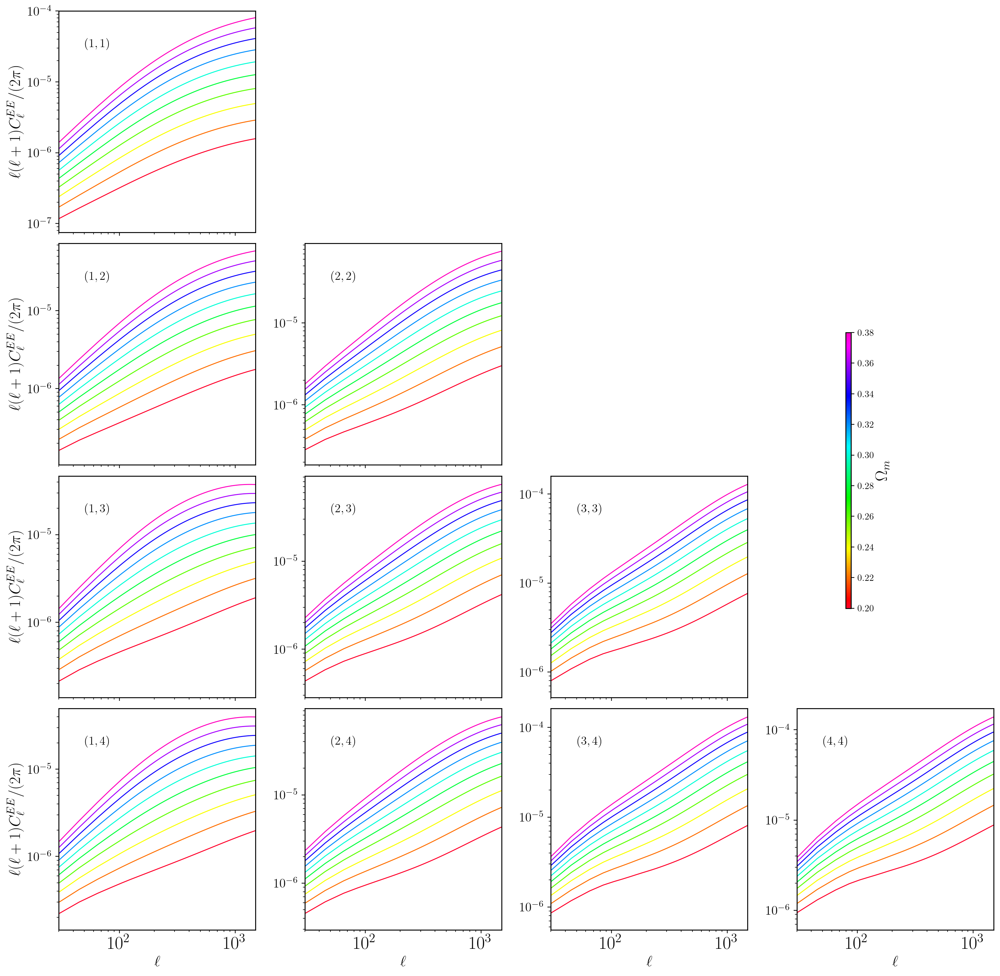

In [12]:
cnu.plot_C_ss_tomo_limber(ell=ell,
                          C_ss=C_ss,
                          param=param,
                          colorbarlabel="$\Omega_m$",
                          yaxislabelsize = 17,
                          yaxisticklabelsize = 14,
                          xaxisticklabelsize = 20)

In [13]:
ell = np.arange(25., 1500., 20.) # Make sure arange are with float numbers (otherwise there are aliasing problems)

param = np.arange(0.85, 1.1, 0.02)

C_ss = []
for x in param:
    (Cl, tmp) = C_ss_tomo_limber(ell=ell, ns=x)
    C_ss.append(Cl)

# Plot the Ratio over ref cosmology
(ref, tmp) = C_ss_tomo_limber(ell=ell)

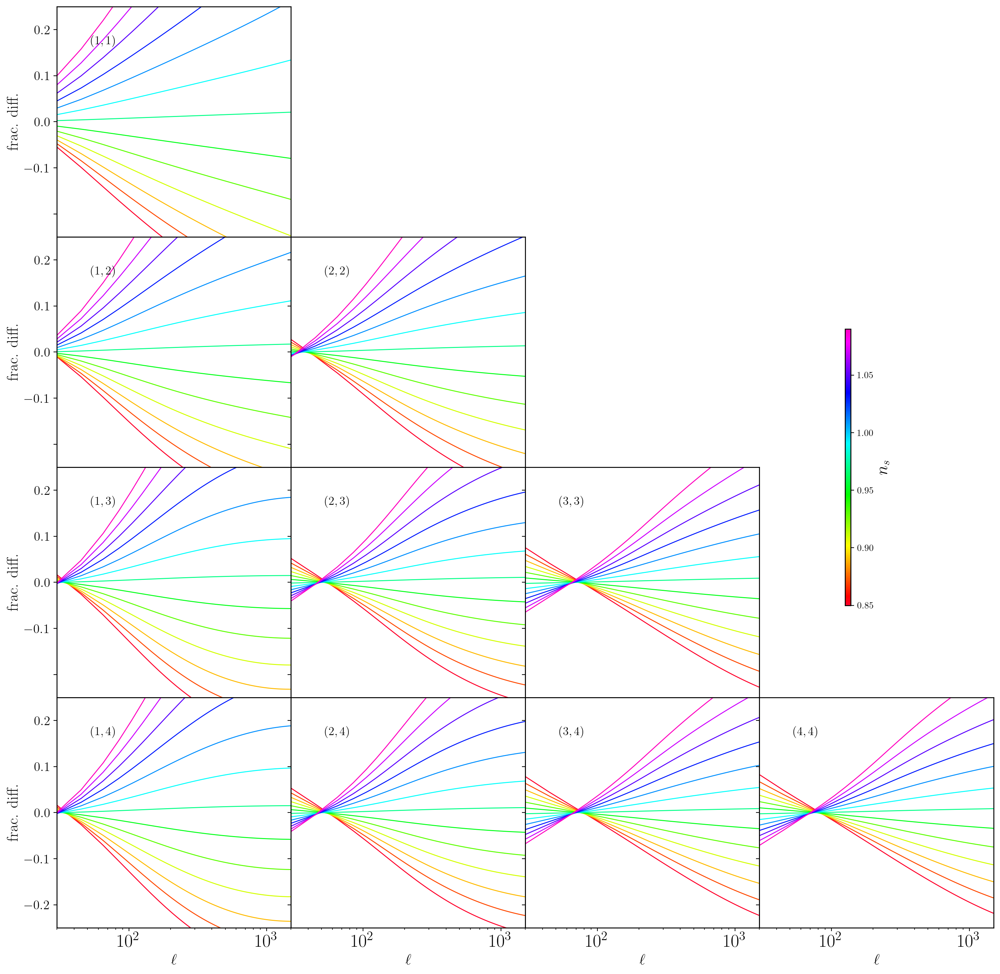

In [14]:
# Reference mode with the default ylim [0.75, 1.25]: the band -25% to +25%
cnu.plot_C_ss_tomo_limber(ell=ell,
                          C_ss=C_ss,
                          C_ss_ref=ref,
                          param=param,
                          colorbarlabel="$n_s$",
                          yaxislabelsize = 17,
                          yaxisticklabelsize = 14,
                          xaxisticklabelsize = 20)

## How $\Omega_m$ changes $\xi_\pm(\theta)$

The sweep varies $\Omega_m$ from 0.20 to 0.40; each entry of `xi_theta` is the
tuple `(theta, xi_plus, xi_minus)` returned by `xi`. `plot_xi` draws $\xi_+$ for
`pm = 1` and $\xi_-$ for `pm = -1`, as $\theta\,\xi\times10^4$; `thetashow` sets the
horizontal range in arcmin.

$\xi_-$ weights higher multipoles than $\xi_+$ at the same angle, so it probes
smaller physical scales, where baryonic feedback and nonlinear modeling matter
most. This is why the DES Y3 mask removes more of $\xi_-$ (61 of 200 entries
kept) than of $\xi_+$ (166 of 200 kept).

In [15]:
param = np.arange(0.2, 0.41, 0.02)
        
xi_theta = []
for x in param:
    # Each entry is the tuple (theta, xi_plus, xi_minus)
    xi_theta.append(xi(omegam = x))

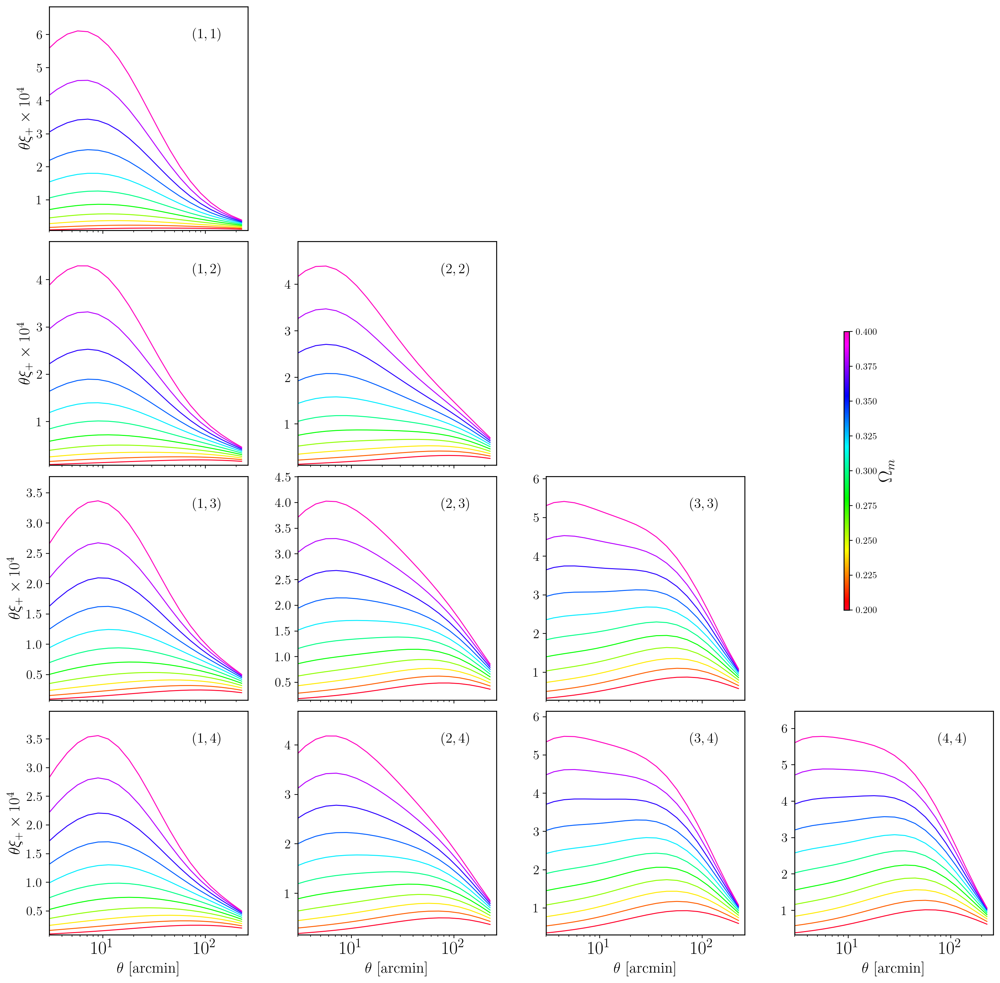

In [16]:
# pm = 1 draws xi_+; thetashow is the horizontal range in arcmin
cnu.plot_xi(pm = 1,
            xi = xi_theta,
            param = param,
            colorbarlabel = "$\Omega_m$",
            thetashow=[3,260],
            yaxislabelsize = 17,
            yaxisticklabelsize = 14,
            xaxisticklabelsize = 20)

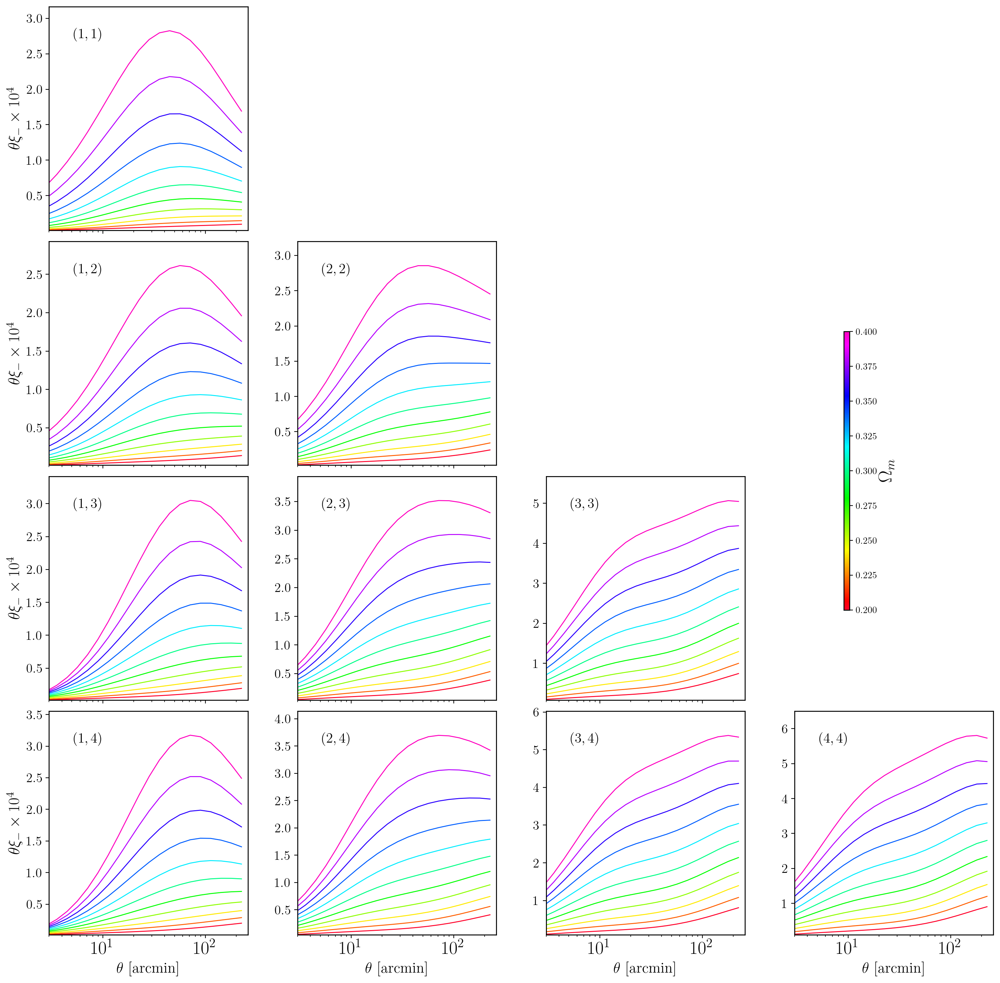

In [17]:
# pm = -1 draws xi_-
cnu.plot_xi(pm = -1,
            xi = xi_theta,
            param = param,
            colorbarlabel = "$\Omega_m$",
            thetashow=[3,260],
            yaxislabelsize = 17,
            yaxisticklabelsize = 14,
            xaxisticklabelsize = 20)

## Changing the angular binning without restarting the kernel

The *kernel* is the Python process that runs the cells. CosmoLike keeps
expensive intermediate results, such as the bin-averaged kernels that turn
$C_\ell$ into $\xi_\pm(\theta)$, in static arrays: C memory that survives between
calls. Each cached table carries a key; `ci.init_binning` assigns a new key
whenever the number of bins or the angular range changes, so the next call
rebuilds the kernels instead of reusing those of the previous binning.

The cell computes $\xi_\pm$ with 9, 12, 17 and 44 bins between 2.5 and 250
arcmin, and the figures mark each binning with its own symbol. The points of all
binnings should follow one smooth curve, wide bins deviating slightly because
each point averages over its bin; a stale cache would instead place the
previous binning's values at the new angles.

In [18]:
nthetas=[9, 12, 17, 44]

result = []
for x in nthetas:
    # A new binning on every call: CosmoLike rebuilds its angular kernels
    result.append(xi(ntheta=x))

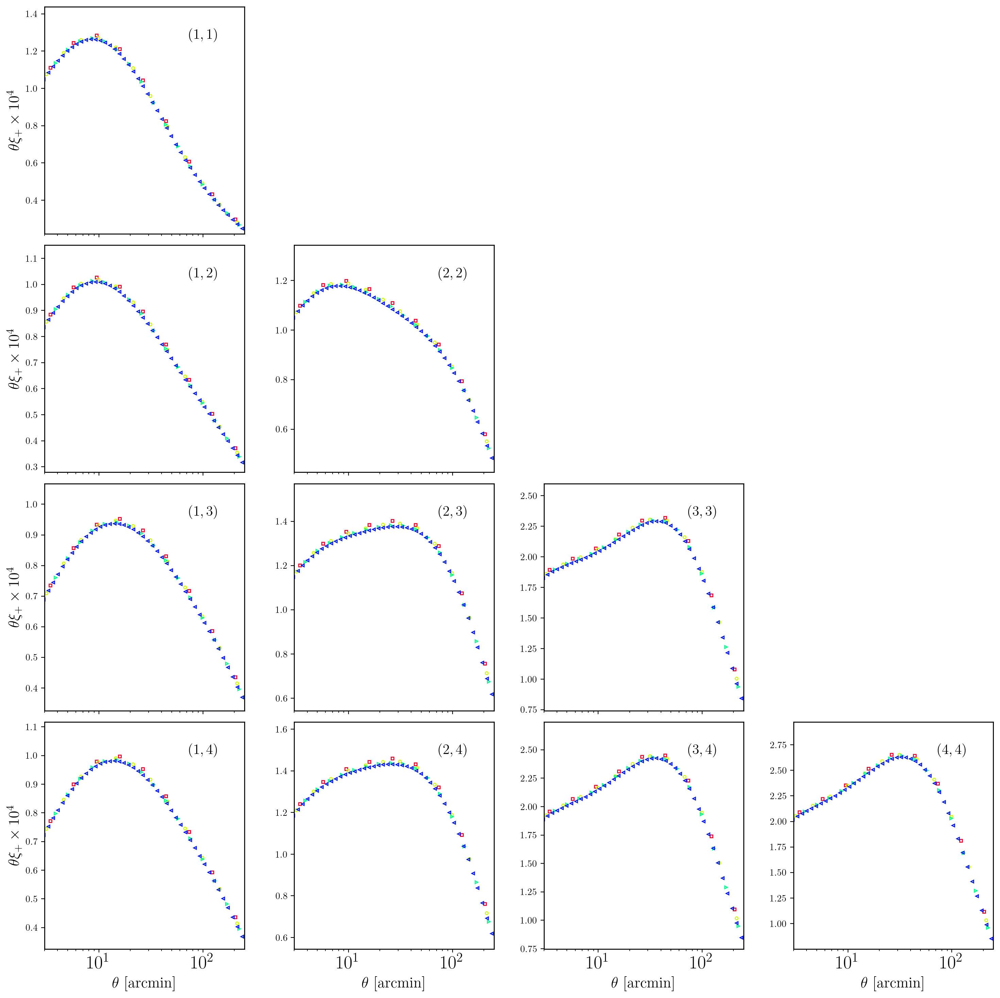

In [19]:
cnu.plot_xi(pm = 1,
            xi = result,
            marker=['s', 'o', ">", "<"])

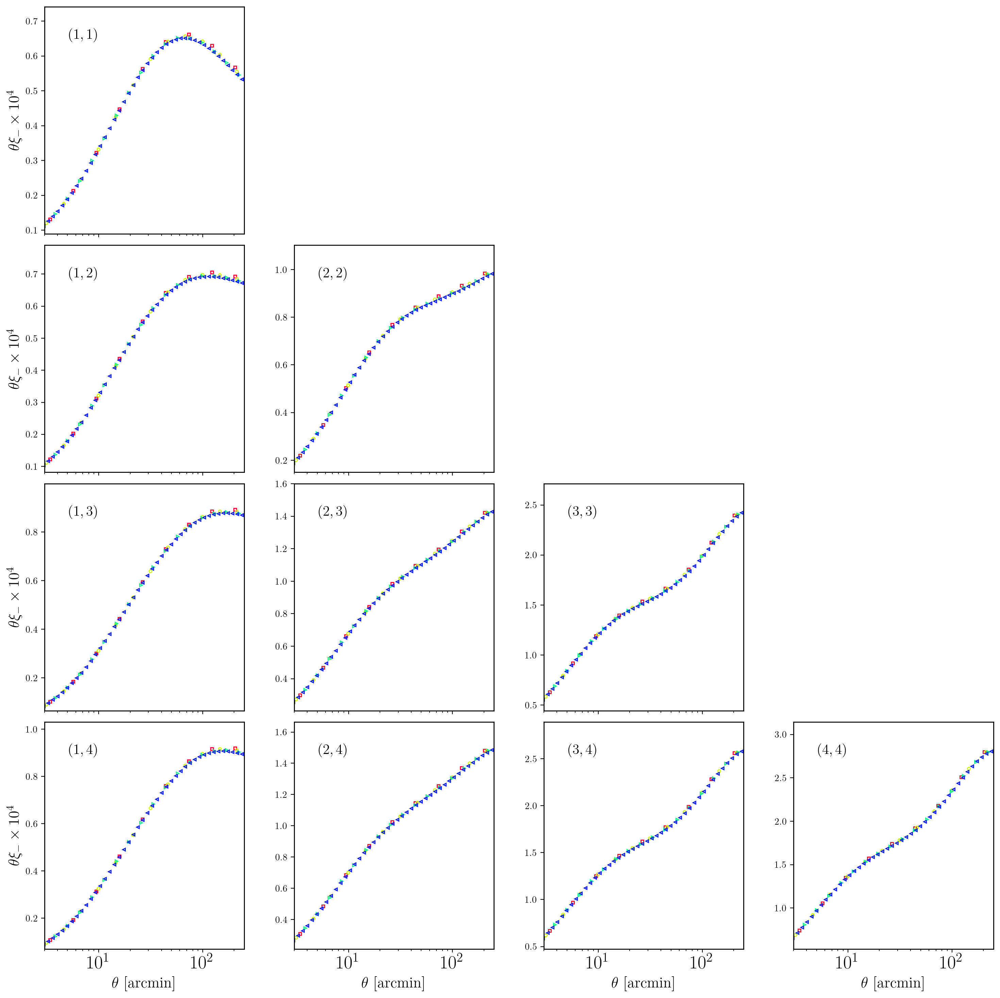

In [20]:
cnu.plot_xi(pm = -1,
            xi = result,
            marker=['s', 'o', ">", "<"])

## Baryonic feedback in $C_\ell^{EE}$ and $\xi_\pm(\theta)$

Gas physics (cooling, star formation, energy injected by supernovae and active
galactic nuclei) moves matter inside and around halos and changes the matter
power spectrum at small scales. `ci.init_baryons_contamination(sim, allsims)`
multiplies CosmoLike's matter power by the ratio of the power spectrum of one
hydrodynamical simulation to that of its dark-matter-only counterpart, tabulated
in the HDF5 file (a binary table format) `baryons_logPkR.h5` named in the dataset.

The cells compute the nine scenarios listed in `param` and the fiducial without
baryons, then draw each scenario relative to the fiducial ($C/C^\mathrm{fid}-1$ and
$\xi/\xi^\mathrm{fid}-1$), named by a legend instead of a colorbar. The real-space
curves use 40 angular bins, for smoother lines.

In [21]:
ell = np.arange(3., 7500., 10.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
# Simulation names in the HDF5 table baryons_logPkR.h5
param = ("TNG100-1", "HzAGN-1", "mb2-1", "illustris-1", "eagle-1", "owls_AGN-1", "owls_AGN-2", "owls_AGN-3", "BAHAMAS-2")
        
C_ss = []
for x in param:
    (Cl, tmp) = C_ss_tomo_limber(ell=ell, baryon_sims=x)
    C_ss.append(Cl)
    
# Plot the Ratio over ref cosmology
(C_ss_ref, tmp) = C_ss_tomo_limber(ell=ell)

xi_theta = []
for x in param:
    # 40 angular bins draw smoother curves than the 20 of the data vector
    xi_theta.append(xi(baryon_sims=x, ntheta=40, AccuracyBoost=1.0))

xi_theta_ref = xi(ntheta=40, AccuracyBoost=1.0)

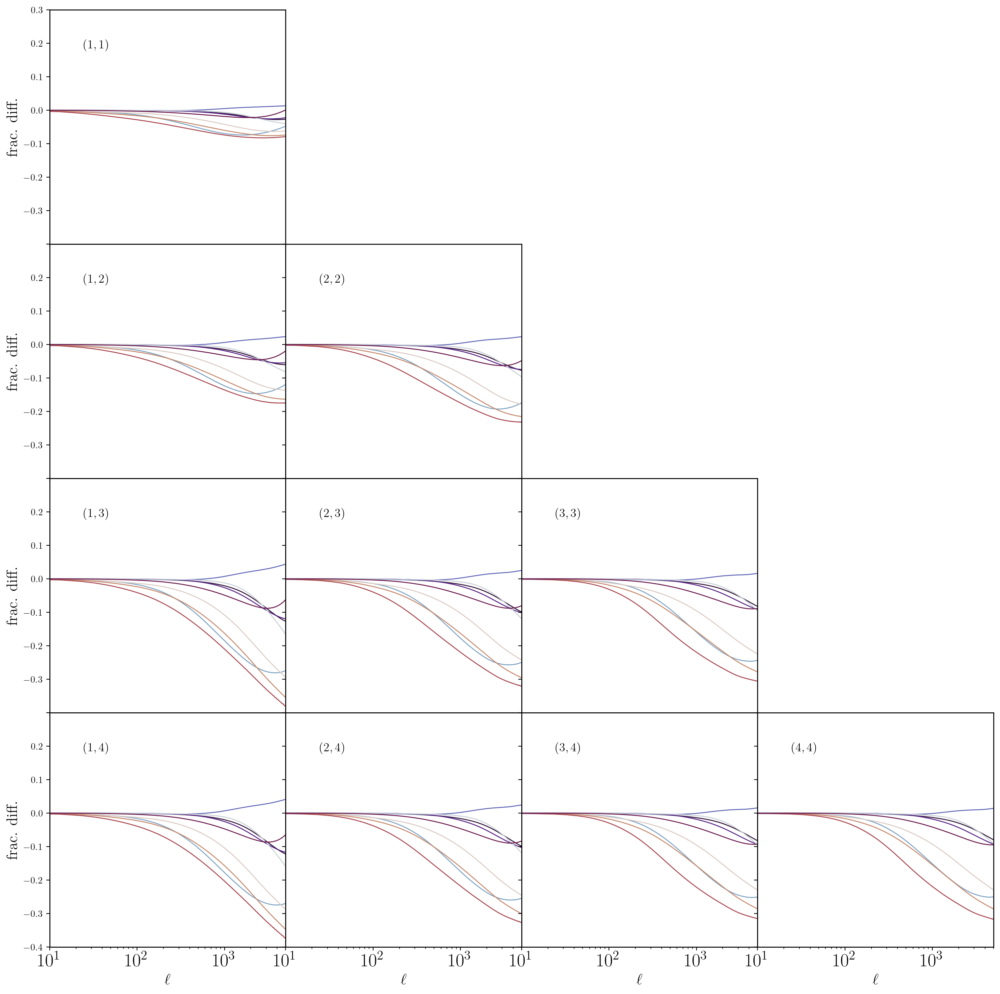

In [22]:
# ylim (0.6, 1.3): the band -40% to +30% of C/C_ref - 1
cnu.plot_C_ss_tomo_limber(ell=ell,
                          C_ss=C_ss,
                          C_ss_ref=C_ss_ref,
                          lmin=10,
                          lmax=5000,
                          cmap="twilight_shifted",
                          ylim=(0.6,1.3))

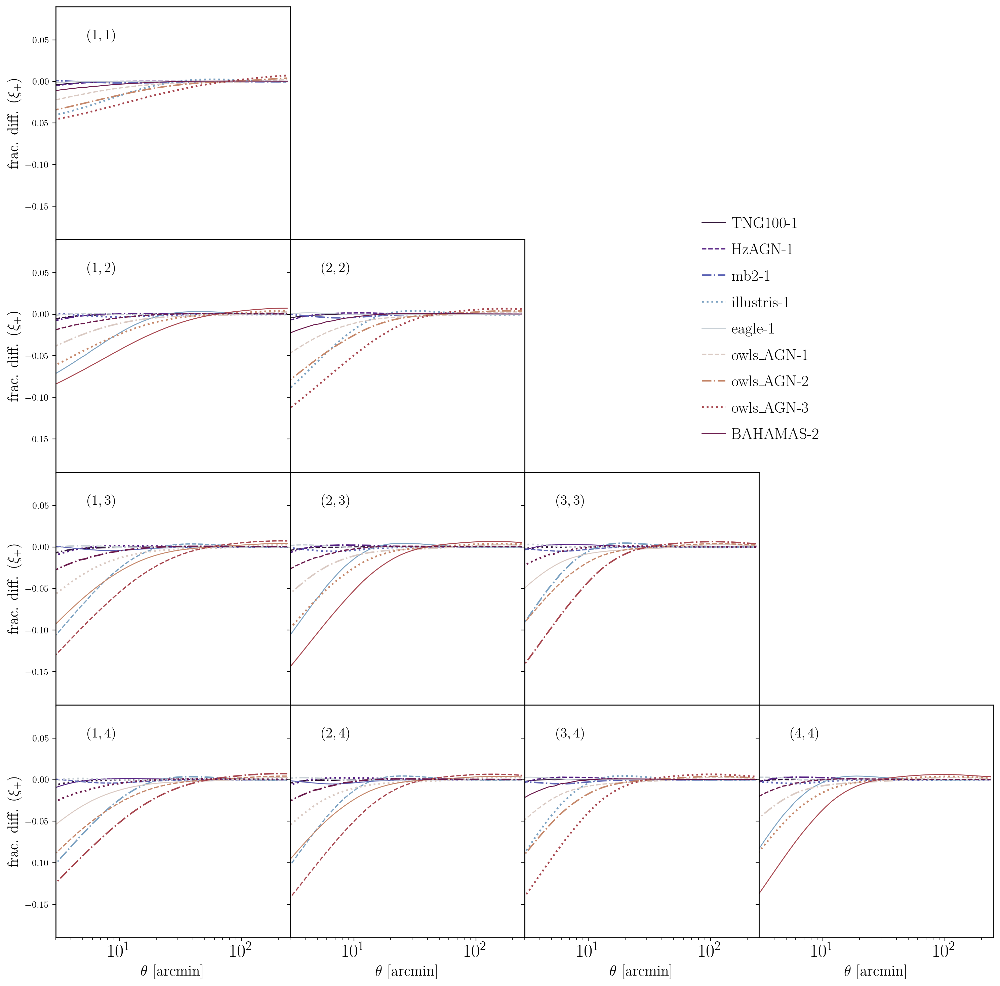

In [23]:
# rcParams are global: every later figure uses this legend font size
matplotlib.rcParams['legend.fontsize'] = 17
 
# legend names the curves instead of a colorbar; ylim (0.81, 1.09) is the
# band -19% to +9% of xi/xi_ref - 1
cnu.plot_xi(pm = 1,
            param=None,
            xi=xi_theta,
            xi_ref=xi_theta_ref,
            cmap="twilight_shifted",
            ylim=(0.81,1.09),
            linewidth=[1.0, 1.3, 1.6, 1.9],
            linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
            legend = param,
            legendloc=(0.7,0.55),
            bintextpos = [[0.2, 0.875],[0.2,0.875]])

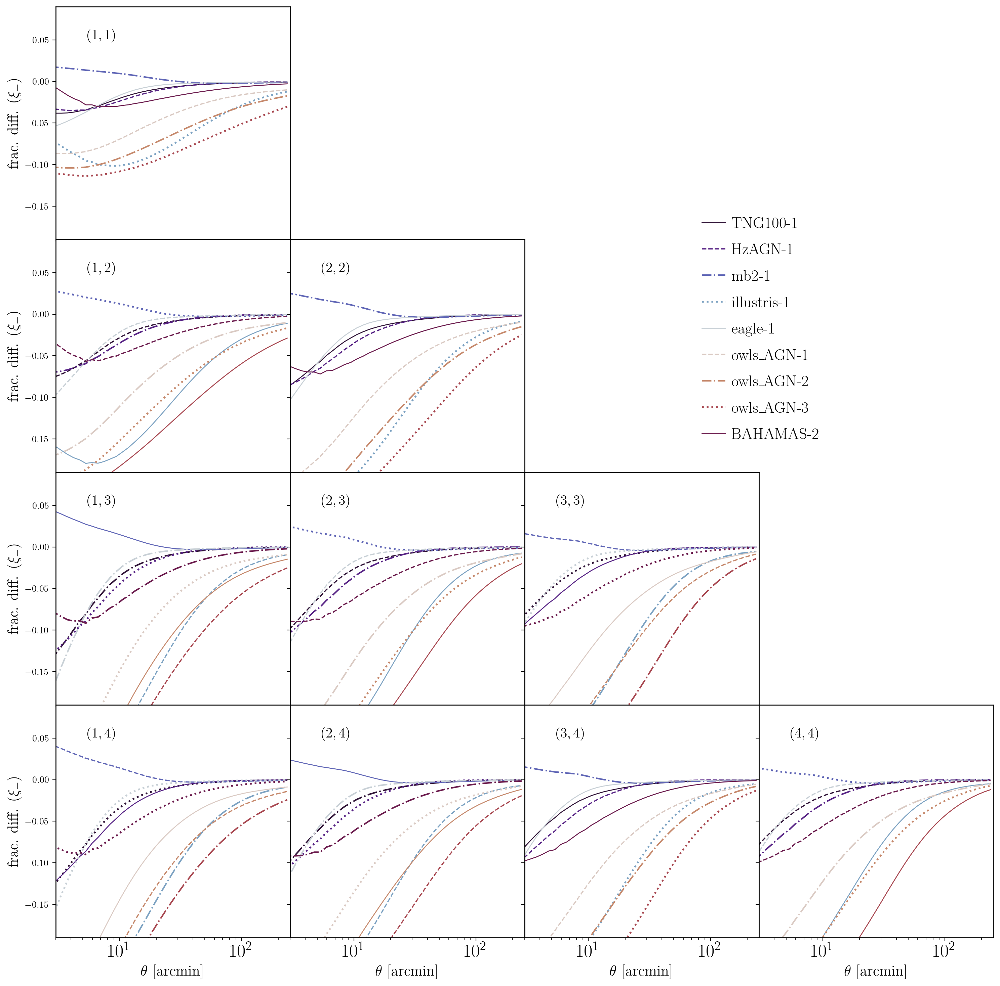

In [24]:
cnu.plot_xi(pm = -1,
            param=None,
            xi=xi_theta,
            xi_ref=xi_theta_ref,
            cmap="twilight_shifted",
            ylim=(0.81,1.09),
            linewidth=[1.0, 1.3, 1.6, 1.9],
            linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
            legend = param,
            legendloc=(0.7,0.55),
            bintextpos = [[0.2, 0.875],[0.2,0.875]])

## Accuracy settings: how `AccuracyBoost` changes $C_\ell^{EE}$ and $\xi_+(\theta)$

`AccuracyBoost` refines three things together: CAMB runs with accuracy
$1.1\times(1+(\texttt{AccuracyBoost}-1)/3)$, the CosmoLike tables and the CAMB
grids grow with `AccuracyBoost`, and the wrapper raises the quadrature level by
$|3(\texttt{AccuracyBoost}-1)|$, rounded down, so a boost below 1 raises it too.

The spectra use `AccuracyBoost` from 0.45 to 1.95 in steps of 0.25 and the
$\xi_+$ curves 0.50 to 1.75, each drawn relative to `AccuracyBoost = 1`, on bands
of $\pm4\%$ and $\pm1\%$. The $\chi^2$ sections below express such differences as
$\Delta\chi^2$ against the DES Y3 covariance.

In [25]:
ell = np.arange(10., 8500., 30.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)

# AccuracyBoost 0.45 to 1.95 refines CAMB, the CosmoLike tables and the
# quadrature level together
param = np.arange(0.45, 2.0, 0.25)
        
C_ss = []
for x in param:
    (Cl, tmp) = C_ss_tomo_limber(ell=ell, AccuracyBoost=x)
    C_ss.append(Cl)

# Plot the Ratio over ref cosmology
(C_ss_ref, tmp) = C_ss_tomo_limber(ell=ell)

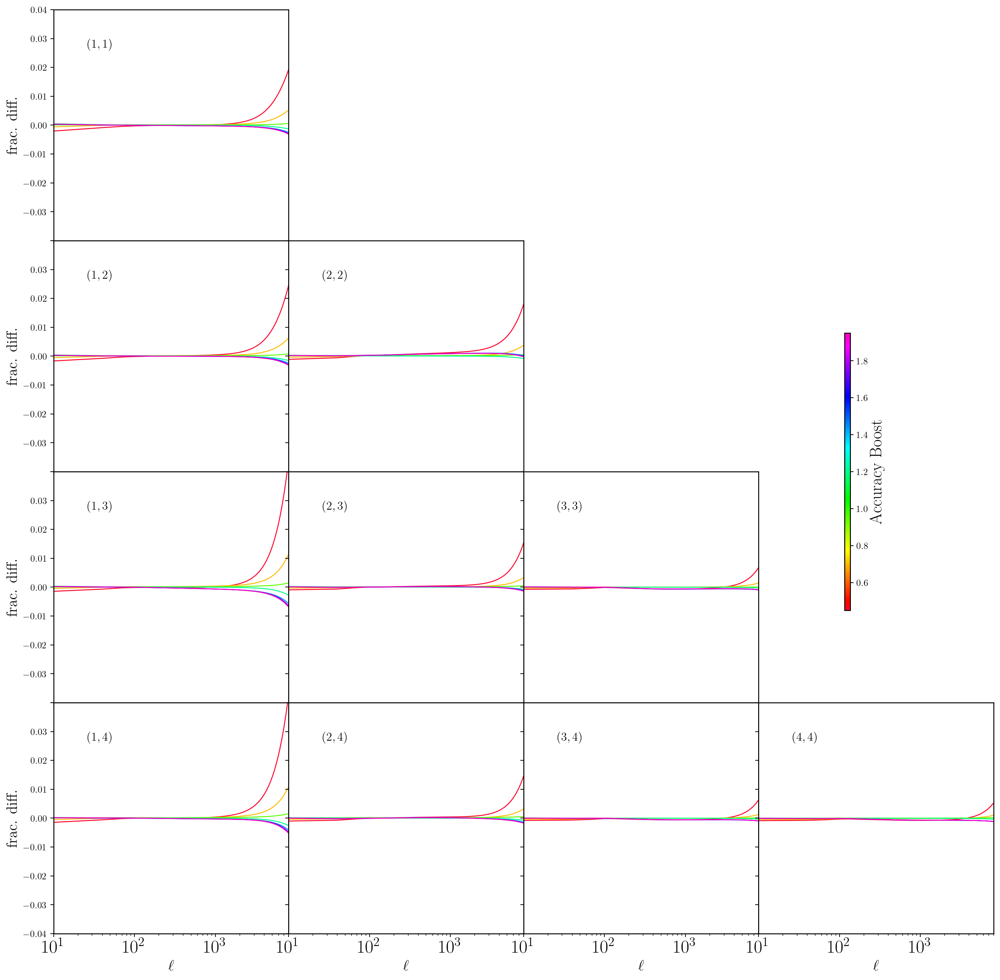

In [26]:
# ylim (0.96, 1.04): the band -4% to +4% of C/C_ref - 1
cnu.plot_C_ss_tomo_limber(ell=ell,
                          C_ss=C_ss,
                          C_ss_ref=C_ss_ref,
                          param=param,
                          lmin=10,
                          lmax=8000,
                          ylim=(0.96,1.04),
                          colorbarlabel="Accuracy Boost")

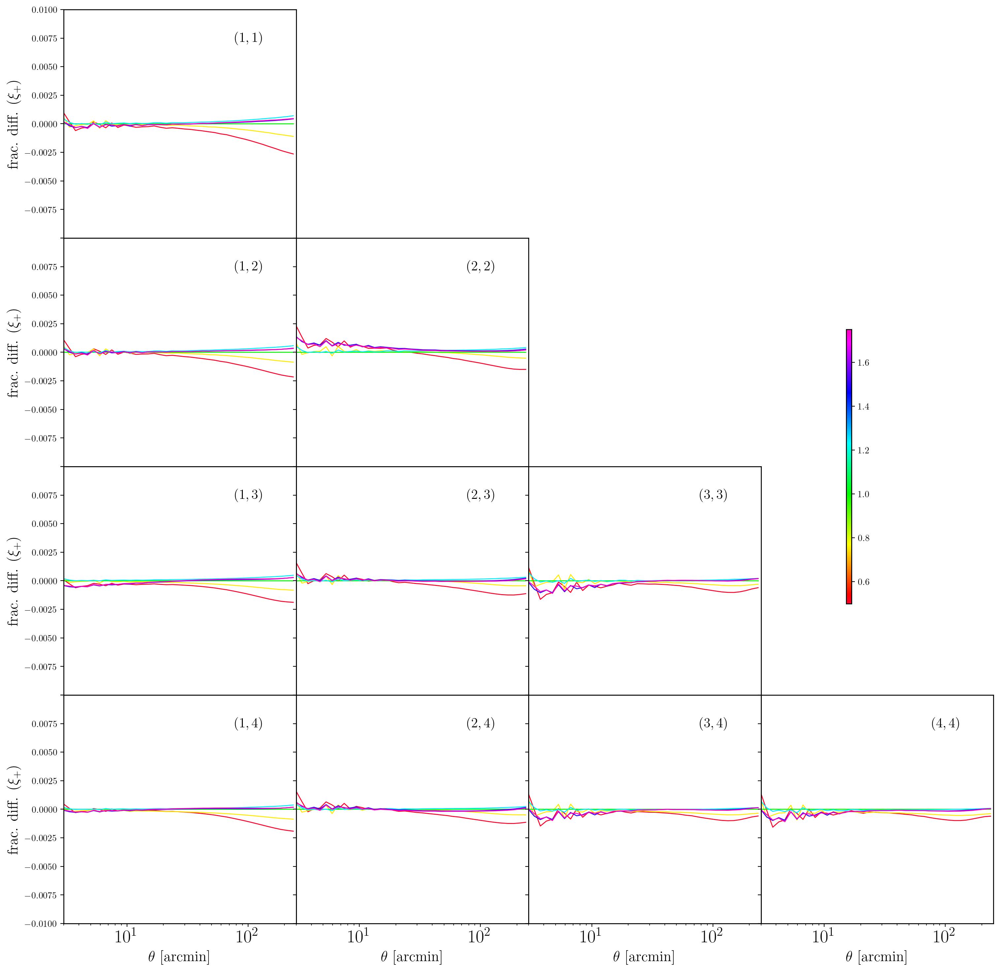

In [27]:
param = np.arange(0.5, 2.0, 0.25)
xi_theta_ref = xi(ntheta=40)

# w_theta holds xi tuples here; the name does not mean clustering w(theta)
w_theta = []
for x in param:
    w_theta.append(xi(ntheta=40, AccuracyBoost=x))
    
# ylim (0.99, 1.01): the band -1% to +1% of xi_+/xi_+ref - 1
cnu.plot_xi(pm = 1,
            xi = w_theta,
            xi_ref = xi_theta_ref,
            param=param,
            ylim=(0.99, 1.01))

## $\chi^2$ against the DES Y3 cosmic-shear data

The next cell initializes CosmoLike again, now with data. `init_probes("xi")`
selects cosmic shear: the mask of every other entry is set to zero, so 227 of the
533 baseline entries remain (166 of $\xi_+$, 61 of $\xi_-$). `init_data_real` reads
the published DES Y3 covariance, the 3×2pt baseline mask and the measured data
vector named in the dataset file.

`get_chi2` runs CAMB and the setters, then

- `compute_data_vector_masked()` returns all 900 entries of the 3×2pt layout,
  masked ones set to zero;
- `compute_chi2(t)` returns $\chi^2=(d-t)^{\mathsf T}C^{-1}(d-t)$ over the retained
  entries only, with $C^{-1}$ the inverse of the retained block of the covariance.

**Comparison with `EXAMPLE_EVALUATE1.yaml`.** The likelihood settings match that
file (TATT with power-law evolution, Halofit, quadrature level 1, `lmax` 50,000),
but two inputs differ, so the printed $\chi^2$ is not the YAML's value: this
notebook uses `DES_A2_1 = -1.79`, where the YAML sets 0.01, and `get_chi2` runs
CAMB with `kmax = 10`/Mpc, `k_per_logint = 20` and CAMB accuracy 1.1, where the
YAML uses 5, 10 and 1.0.

In [28]:
non_linear_emul = 2
CLprobe="xi"

path= "../../external_modules/data/des_y3"
data_file="des_y3_real.dataset"

IA_model = 1
IA_redshift_evolution = 3
IA_code = 0

# Init Cosmolike & data file
ini = IniFile(os.path.normpath(os.path.join(path, data_file)))

lens_file = ini.relativeFileName('nz_lens_file')
source_file = ini.relativeFileName('nz_source_file')
lens_ntomo = ini.int("lens_ntomo")
source_ntomo = ini.int("source_ntomo")

ci.initial_setup()

# initial_setup resets the FAST-PT grid fraction to the C default;
# set it again before get_chi2 calls init_accuracy_boost
ci.init_fpt_internal_boost(internal_boost = float(internal_accuracyboost))

# xi: only the cosmic-shear entries keep their mask (227 of the 533)
ci.init_probes(possible_probes = CLprobe)

ci.init_binning(int(ini.int("n_theta")), 
                ini.float("theta_min_arcmin"), 
                ini.float("theta_max_arcmin"))


ci.init_cosmo_runmode(is_linear = False)

ci.init_IA( ia_model = int(IA_model), 
            ia_redshift_evolution = int(IA_redshift_evolution),
            ia_code = int(IA_code))

ci.init_redshift_distributions_from_files(
      lens_multihisto_file=ini.relativeFileName('nz_lens_file'),
      lens_ntomo=int(ini.int("lens_ntomo")), 
      source_multihisto_file=ini.relativeFileName('nz_source_file'),
      source_ntomo=int(ini.int("source_ntomo")))

# The published DES Y3 covariance, the 3x2pt baseline mask and the
# measured data vector named in the dataset file
ci.init_data_real(ini.relativeFileName('cov_file'), 
                  ini.relativeFileName('mask_file'), 
                  ini.relativeFileName('data_file'))

def get_chi2(omegam = omegam, 
             omegab = omegab, 
             H0 = H0, 
             ns = ns, 
             As_1e9 = As_1e9, 
             w = w, 
             w0pwa = w0pwa,
             A1  = [DES_A1_1, DES_A1_2, 0, 0], 
             A2  = [DES_A2_1, DES_A2_2, 0, 0],
             BTA = [DES_BTA_1, 0, 0, 0],
             shear_photoz_bias = [DES_DZ_S1, DES_DZ_S2, DES_DZ_S3, DES_DZ_S4],
             M = [DES_M1, DES_M2, DES_M3, DES_M4],
             baryon_sims = None,
             AccuracyBoost=1.0, 
             kmax = 10, 
             k_per_logint = 20, 
             CAMBAccuracyBoost=1.1,
             CLAccuracyBoost=1.0, 
             CLIntegrationAccuracy=1):

    CLAccuracyBoost = CLAccuracyBoost * AccuracyBoost
    CLIntegrationAccuracy = max(0, CLIntegrationAccuracy + abs(3*(CLAccuracyBoost-1.0)))

    ci.init_ntable_lmax(int(50000 + 20000*(CLAccuracyBoost-1)))
    ci.init_accuracy_boost(CLAccuracyBoost, int(CLIntegrationAccuracy))
    ci.init_photoz_conventions(
        int(photoz_interpolation_type),
        int(photoz_zmid_convention))
    
    # CAMB with kmax = 10/Mpc, k_per_logint = 20 and CAMB accuracy 1.1 fixed
    # here: this call ignores the kmax, k_per_logint, CAMBAccuracyBoost and
    # AccuracyBoost arguments of get_chi2.
    (log10k_interp_2D, z_interp_2D, lnPL, lnPNL, G_growth, z_growth, z_interp_1D, chi,
     omegan2, lnPL_cb) = cnu.get_camb_cosmology(omegam=omegam,
        omegab=omegab, H0=H0, ns=ns, As_1e9=As_1e9, w=w, w0pwa=w0pwa,
        mnu=mnu, non_linear_emul=non_linear_emul, kmax=10,
        k_per_logint=20, CAMBAccuracyBoost=1.1,
        CLAccuracyBoost=CLAccuracyBoost)
    
    ci.set_cosmology(omegam = omegam, 
                     H0 = H0, 
                     log10k_2D = log10k_interp_2D, 
                     z_2D = z_interp_2D, 
                     lnP_linear = lnPL,
                     lnP_nonlinear = lnPNL,
                     G = G_growth,
                     z_G = z_growth,
                     z_1D = z_interp_1D,
                     chi = chi,
                     omegan2 = omegan2)
    
    ci.set_nuisance_shear_calib(M = M)
    
    ci.set_nuisance_shear_photoz(bias = shear_photoz_bias)
    
    ci.set_nuisance_ia(A1 = A1, 
                       A2 = A2, 
                       B_TA = BTA)
    
    # All 900 entries, masked ones set to zero; compute_chi2 forms
    # (d - t)^T C^-1 (d - t) over the retained entries only
    datavector = np.array(ci.compute_data_vector_masked())
    return ci.compute_chi2(datavector)

In [29]:
# Not the value of EXAMPLE_EVALUATE1.yaml: DES_A2_1 and the CAMB settings
# differ (see the markdown above)
print(rf"$\chi^2$={get_chi2():3.3f}")

$\chi^2$=596.261


## Quadrature check: $\Delta\chi^2$ against the integration level

The next cell evaluates $\chi^2$ at quadrature levels 0 to 9, everything else
fixed, and subtracts the level-0 value; the plot after it shows
$\Delta\chi^2=\chi^2(\text{level})-\chi^2(0)$ against the level (the figure has no
axis labels). Each level selects a fixed Gauss–Legendre rule, a set of points
and weights for the line-of-sight integrals: for the shear spectra 96, 128,
256, 512 and 1024 points at levels 0 to 4. Higher levels reuse the 1024-point
rule, so the curve is flat beyond level 4. The project's tests treat
$|\Delta\chi^2|<0.2$ as numerically negligible.

In [30]:
param = np.arange(0, 10, 1)      
chi2 = []
for x in param:
    chi2.append(get_chi2(CLIntegrationAccuracy = x))
chi2 = np.array(chi2)
# Delta chi^2 relative to quadrature level 0
chi2 = chi2 - chi2[0]

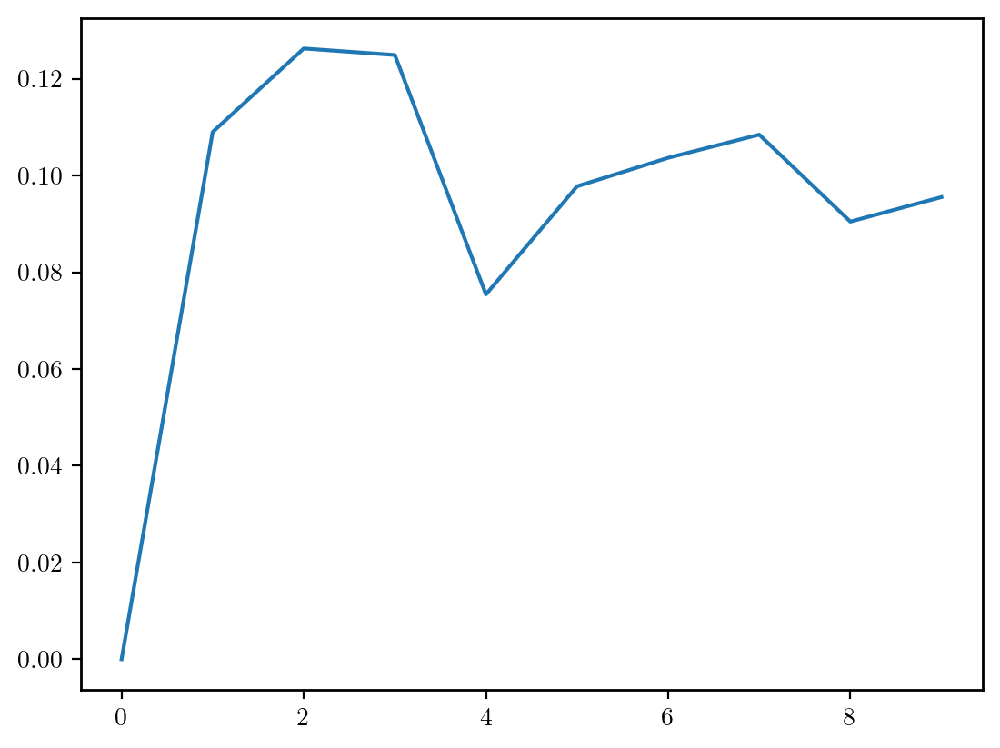

In [31]:
# Horizontal: quadrature level; vertical: Delta chi^2 (no axis labels)
plt.plot(param, np.array(chi2))

## Interpolation check: $\Delta\chi^2$ against `CLAccuracyBoost`

The next cell evaluates $\chi^2$ at `CLAccuracyBoost` = 1, 2, ..., 9 and
subtracts the boost-1 value. This boost multiplies the sizes of CosmoLike's
interpolation tables and the redshift and wavenumber grids of the CAMB tables,
and raises the multipole cutoff of `init_ntable_lmax` by 20,000 per unit;
CAMB's own accuracy stays fixed. Although the call passes
`CLIntegrationAccuracy = 1`, `get_chi2` raises the quadrature level to
$1+3(\text{boost}-1)$, so this scan refines interpolation and quadrature
together; from boost 2 on, the quadrature already uses its largest rule. The
plot has no axis labels: horizontal is the boost, vertical $\Delta\chi^2$.

In [32]:
param = np.arange(1, 10, 1)      
chi2 = []
for x in param:
    chi2.append(get_chi2(CLAccuracyBoost=x, CLIntegrationAccuracy = 1))
chi2 = np.array(chi2)
# Delta chi^2 relative to CLAccuracyBoost = 1; the quadrature level is
# 1 + 3 (boost - 1), so it rises with the boost
chi2 = chi2 - chi2[0]

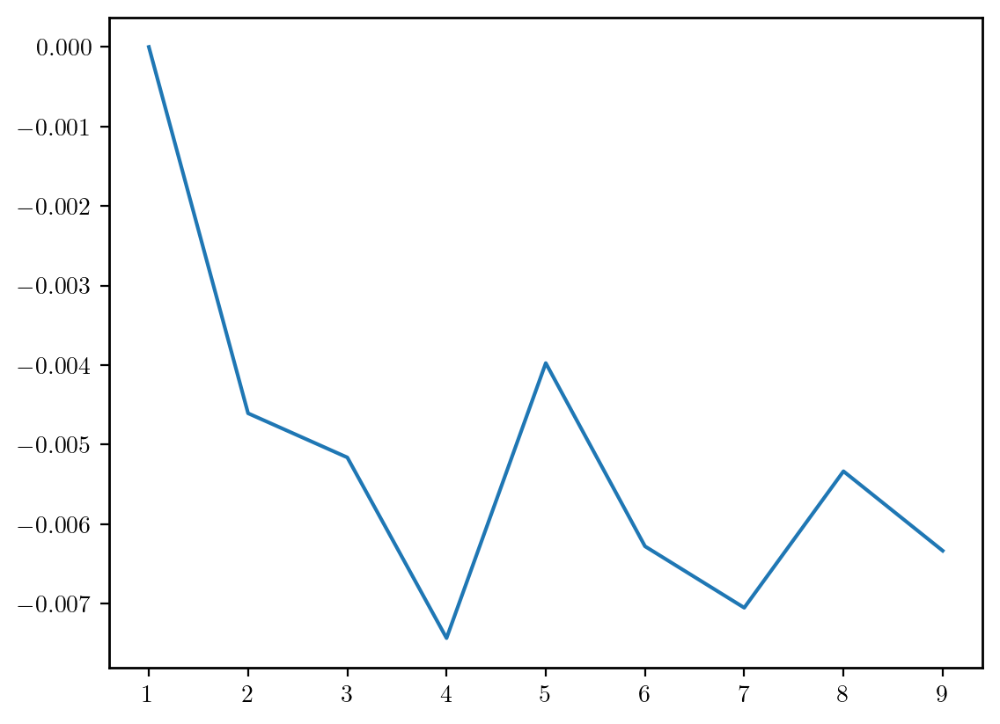

In [33]:
# Horizontal: CLAccuracyBoost; vertical: Delta chi^2 (no axis labels)
plt.plot(param, np.array(chi2))

<!-- DRAFT: Fable rewrites -->
## Fisher forecasts

For a Gaussian likelihood, the Fisher matrix

$$F_{ab}=\sum_{ij}\frac{\partial m_i}{\partial p_a}\,(C^{-1})_{ij}\,\frac{\partial m_j}{\partial p_b}$$

approximates the inverse of the parameter covariance near the fiducial point:
$F^{-1}$ is the forecast parameter covariance. Here $m$ is the masked
cosmic-shear data vector (`init_probes("xi")` with the 3×2pt baseline mask:
227 of the 900 entries) and $C^{-1}$ the inverse of the published DES Y3
covariance over those entries (`ci.get_inv_cov_masked()`).

**Parameters.** $p$ holds the 20 entries of `nw.FISHER_PARAM_NAMES`: $10^9A_s$,
$n_s$, $H_0$, $\Omega_b$, $\Omega_m$, $w_0$, $w_a$ (indices 0–6), the five TATT
parameters $A_1$, $\eta_1$, $A_2$, $\eta_2$, $b_\mathrm{TA}$ (7–11), the four source
photo-z shifts (12–15) and the four shear calibrations (16–19). The fiducial is
the notebook's (`DES_A2_1` $=-1.79$, not the 0.01 of `EXAMPLE_EVALUATE1.yaml`),
with $w_0=-0.9$ and $w_a=0$ free; $\sum m_\nu=0.06$ eV stays fixed. Gaussian
priors from `likelihood/params_source.yaml` add $1/\sigma^2$ to the diagonal:
widths 0.018, 0.015, 0.011, 0.017 on the photo-z shifts and 0.009, 0.008,
0.008, 0.008 on the shear calibrations. The flat priors of the YAML only clip
the plotted contours.

**Derivatives.** Five-point stencil with relative step $h$, $\delta=h\,p$, at
$p\pm\delta$ and $p\pm2\delta$; a parameter whose fiducial is zero ($w_a$) takes
the absolute step $\delta=h$. Four data vectors per parameter, 80 per Fisher
matrix. `nw.get_dv` passes `AccuracyBoost` both to CAMB and the grids and as
`CLAccuracyBoost`, so CosmoLike's own boost is `AccuracyBoost`$^2$.

**Figures of merit.** $\mathrm{FoM}=1/\sqrt{\det C_2}$, with $C_2$ the $2\times2$
block of $F^{-1}$ of a parameter pair (marginalized over everything else): the
pair $(w_0,w_a)$, the one of the FoM-noise subsection, and
$(10^9A_s,\Omega_m)$, the pair the roman_real and lsst_y1 notebooks quote.
Cosmic shear alone constrains $w_0$ and $w_a$ weakly, so their contours fill
much of the $w_0$ prior box.

This project has no example MCMC chain, so the last test compares the stencil
with derivkit only.

In [34]:
# nw: this project's notebook wrappers (projects/des_y3/interface): the
# probe, chi2 and Fisher wrappers. The cells above keep their own
# helpers; the sections from here on use nw.
import time
import cosmolike_des_y3_notebook_wrappers as nw
print('Using notebook wrappers installed at %s' % (nw.__file__))

# ---------------------------------------------------------------------------
# Caution: Fisher derivatives and CAMB's halofit
# ---------------------------------------------------------------------------
# The derivatives below difference the data vector between nearby
# cosmologies. Stock CAMB stops halofit's bisection for the nonlinear scale
# at |sigma(R) - 1| <= 1e-3; where it stops jumps between nearby
# cosmologies and shifts the nonlinear P(k) of whole redshift slices by
# ~0.3%, so the figure of merit moves with the step h. Cocoa's patch (key
# PATCH_CAMB_HALOFIT_TOLERANCE in set_installation_options.sh) stops it at
# 1e-7; external_modules/code/CAMB/fortran/halofit.f90 shows which
# tolerance the installed source has. To apply the patch: set the key,
# export OVERWRITE_EXISTING_CAMB_CODE=1, then source
# installation_scripts/setup_camb.sh and installation_scripts/compile_camb.sh.
# ---------------------------------------------------------------------------
ini = nw.init_cosmolike(CLprobe="xi", with_data=True)
param = nw.fisher_fiducial_point()
param_names = nw.FISHER_PARAM_NAMES
param_labels = nw.FISHER_PARAM_LABELS
flat_priors = nw.FISHER_FLAT_PRIORS
gaussian_priors = nw.FISHER_GAUSSIAN_PRIORS
# C^-1 as CosmoLike holds it: masked rows and columns are zero
invcov = np.array(ci.get_inv_cov_masked())
# the indices of the two figure-of-merit pairs
iw0 = param_names.index("w0")
iwa = param_names.index("wa")
iAs = param_names.index("As_1e9")
iOm = param_names.index("omegam")
# the seven cosmological parameters, drawn in the triangle plots; the
# other 13 are marginalized
sel = [0, 1, 2, 3, 4, 5, 6]
print(f"{len(param)} parameters; {int(np.sum(np.diag(invcov) != 0))} data "
      "points enter F")

Using notebook wrappers installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_y3/interface/cosmolike_des_y3_notebook_wrappers.py


20 parameters; 227 data points enter F


<!-- DRAFT: Fable rewrites -->
### A first Fisher matrix

One Fisher matrix with $h=0.025$ and `AccuracyBoost` = 2.5, the settings of the
lsst_y1 notebook: derivatives amplify the numerical noise of the data vector, so
they need more accurate evaluations than a single $\chi^2$. The cells print the
two FoMs and the marginalized errors of the cosmological parameters, and draw
their forecast contours with getdist. This matrix is also the base $F$ of the
FoM-noise subsection.

In [35]:
# h: relative stencil step (absolute for wa). AccuracyBoost reaches every
# data vector the derivatives evaluate, four per parameter.
t0 = time.perf_counter()
F_base = nw.get_Fisher(CV=param, h=0.025, AccuracyBoost=2.5)
seconds_base = time.perf_counter() - t0
base_label = "h = 0.025, AccuracyBoost = 2.5"
print(f"{4*len(param)} data vectors in {seconds_base:.0f} s")
print(f"FoM(w0, wa)            = {cnu.get_FoM(iw0, iwa, F_base):.4g}")
print(f"FoM(10^9 A_s, Omega_m) = {cnu.get_FoM(iAs, iOm, F_base):.4g}")
# marginalized errors: square roots of the diagonal of F^-1
cov_base = np.linalg.inv(0.5*(F_base + F_base.T))
for k in sel:
    print(f"  sigma({param_names[k]:>6s}) = {np.sqrt(cov_base[k, k]):10.4g}"
          f"   (fiducial {param[k]:.5g})")

80 data vectors in 278 s
FoM(w0, wa)            = 0.03131
FoM(10^9 A_s, Omega_m) = 0.397
  sigma(As_1e9) =      6.648   (fiducial 2.1)
  sigma(    ns) =      0.431   (fiducial 0.96605)
  sigma(    H0) =      186.8   (fiducial 67.32)
  sigma(omegab) =     0.3167   (fiducial 0.04)
  sigma(omegam) =     0.4486   (fiducial 0.3)
  sigma(    w0) =      6.786   (fiducial -0.9)
  sigma(    wa) =      25.27   (fiducial 0)


Removed no burn in


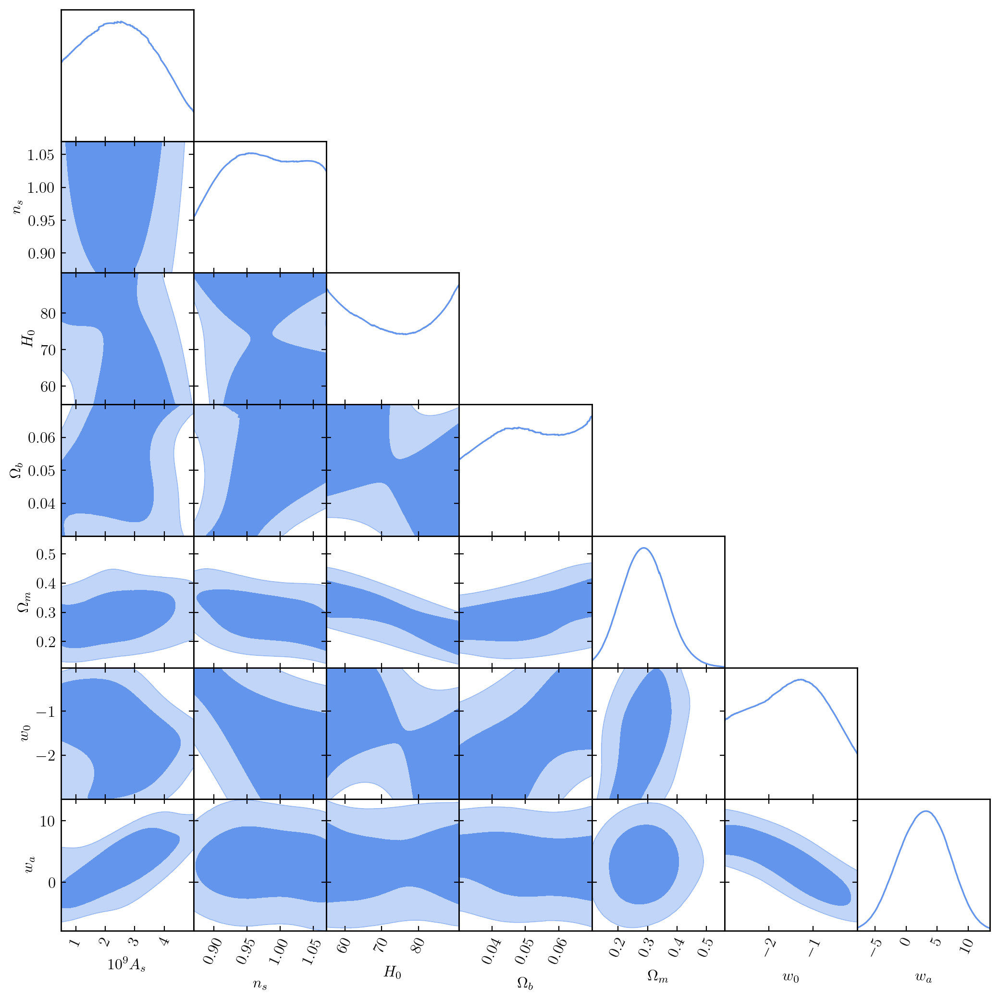

In [36]:
# contours of the seven cosmological parameters, the 13 nuisance
# parameters marginalized; the samples are clipped to the flat priors
g = nw.plot_Fisher(F=F_base,
                   mu=param,
                   select=sel,
                   filled=True,
                   flat_priors=flat_priors)

<!-- DRAFT: Fable rewrites -->
### Test 1: dependence on `AccuracyBoost`

Five Fisher matrices with `AccuracyBoost` from 1 to 5 at $h=0.03$. A converged
forecast has FoMs that stop changing as the boost grows. The figure shows each
FoM divided by its value at `AccuracyBoost` = 5 (dashed line at 1); the
triangle overlays the five sets of contours.

In [37]:
# One Fisher matrix per AccuracyBoost = 1, ..., 5, each from 80 data vectors
AB1 = np.arange(1.0, 6.0, 1.0)
F1 = []
FOM1_w = []
FOM1_AsOm = []
for x in AB1:
    t0 = time.perf_counter()
    F = nw.get_Fisher(CV=param, h=0.03, AccuracyBoost=x)
    F1.append(F)
    FOM1_w.append(cnu.get_FoM(iw0, iwa, F))
    FOM1_AsOm.append(cnu.get_FoM(iAs, iOm, F))
    print(f"AccuracyBoost = {x:g}: FoM(w0, wa) = {FOM1_w[-1]:.4g}, "
          f"FoM(10^9 A_s, Omega_m) = {FOM1_AsOm[-1]:.4g} "
          f"({time.perf_counter() - t0:.0f} s)", flush=True)

AccuracyBoost = 1: FoM(w0, wa) = 0.03228, FoM(10^9 A_s, Omega_m) = 0.4124 (89 s)


AccuracyBoost = 2: FoM(w0, wa) = 0.03116, FoM(10^9 A_s, Omega_m) = 0.3979 (206 s)


AccuracyBoost = 3: FoM(w0, wa) = 0.03131, FoM(10^9 A_s, Omega_m) = 0.3981 (370 s)


AccuracyBoost = 4: FoM(w0, wa) = 0.03131, FoM(10^9 A_s, Omega_m) = 0.3975 (588 s)


AccuracyBoost = 5: FoM(w0, wa) = 0.03131, FoM(10^9 A_s, Omega_m) = 0.3977 (999 s)


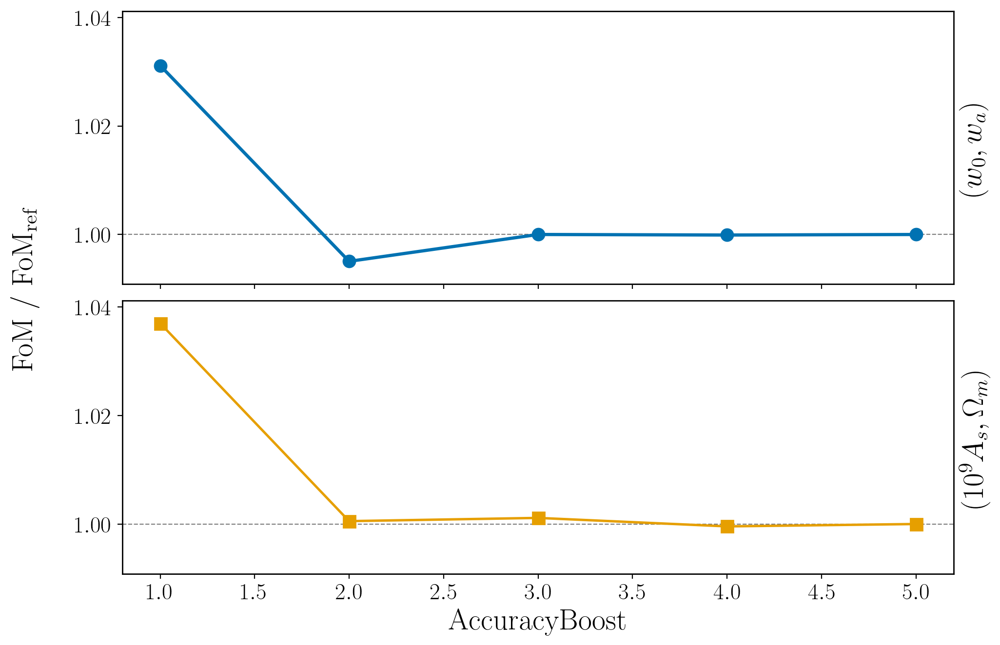

In [38]:
# plot_fom_ratio draws the two figures of merit of a test against the
# setting it varies, each divided by its value at a reference setting:
# two stacked panels sharing the x axis and one y range, the pair named
# by a right-hand y label, so no legend sits on the data.
def plot_fom_ratio(x, fom_w, fom_AsOm, reference, xlabel):
    """Draw FoM/FoM(reference) of (w0, wa) and (10^9 A_s, Omega_m) against x.

    Arguments:
      x         = 1D array of the varied setting (AccuracyBoost or h).
      fom_w     = FoM(w0, wa) at each x.
      fom_AsOm  = FoM(10^9 A_s, Omega_m) at each x.
      reference = index into x of the reference setting (ratio 1).
      xlabel    = the x-axis label.

    Returns:
      nothing; the figure is drawn.
    """
    x = np.asarray(x, dtype=float)
    ratio_w = np.asarray(fom_w)/fom_w[reference]
    ratio_AsOm = np.asarray(fom_AsOm)/fom_AsOm[reference]
    # one y range for both panels: the data and the reference value 1,
    # with 10% of the span added at each end
    low = min(np.min(ratio_w), np.min(ratio_AsOm), 1.0)
    high = max(np.max(ratio_w), np.max(ratio_AsOm), 1.0)
    pad = 0.1*max(high - low, 1e-3)
    fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(11, 7.5),
                             sharex=True, gridspec_kw={"hspace": 0.06})
    # colorblind-safe blue and orange, each with its own width and marker
    styles = [(ratio_w, r"$(w_0, w_a)$", "#0072B2", 2.4, "o"),
              (ratio_AsOm, r"$(10^9 A_s, \Omega_m)$", "#E69F00", 1.8, "s")]
    for ax, (ratio, name, color, width, marker) in zip(axes, styles):
        # the reference value: a thin gray line, named in the text
        ax.axhline(y=1.0, color="gray", linestyle="dashed", linewidth=0.8,
                   zorder=0)
        ax.plot(x, ratio, color=color, linewidth=width, marker=marker,
                markersize=9)
        ax.set_ylim(low - pad, high + pad)
        ax.yaxis.set_label_position("right")
        ax.set_ylabel(name, fontsize=22)
        ax.tick_params(labelsize=17)
    axes[1].set_xlabel(xlabel, fontsize=22)
    fig.supylabel(r"FoM / FoM$_{\rm ref}$", fontsize=22)
    plt.show()


# reference: AccuracyBoost = 5, the last entry
plot_fom_ratio(x=AB1, fom_w=FOM1_w, fom_AsOm=FOM1_AsOm,
               reference=len(AB1) - 1, xlabel="AccuracyBoost")

Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in


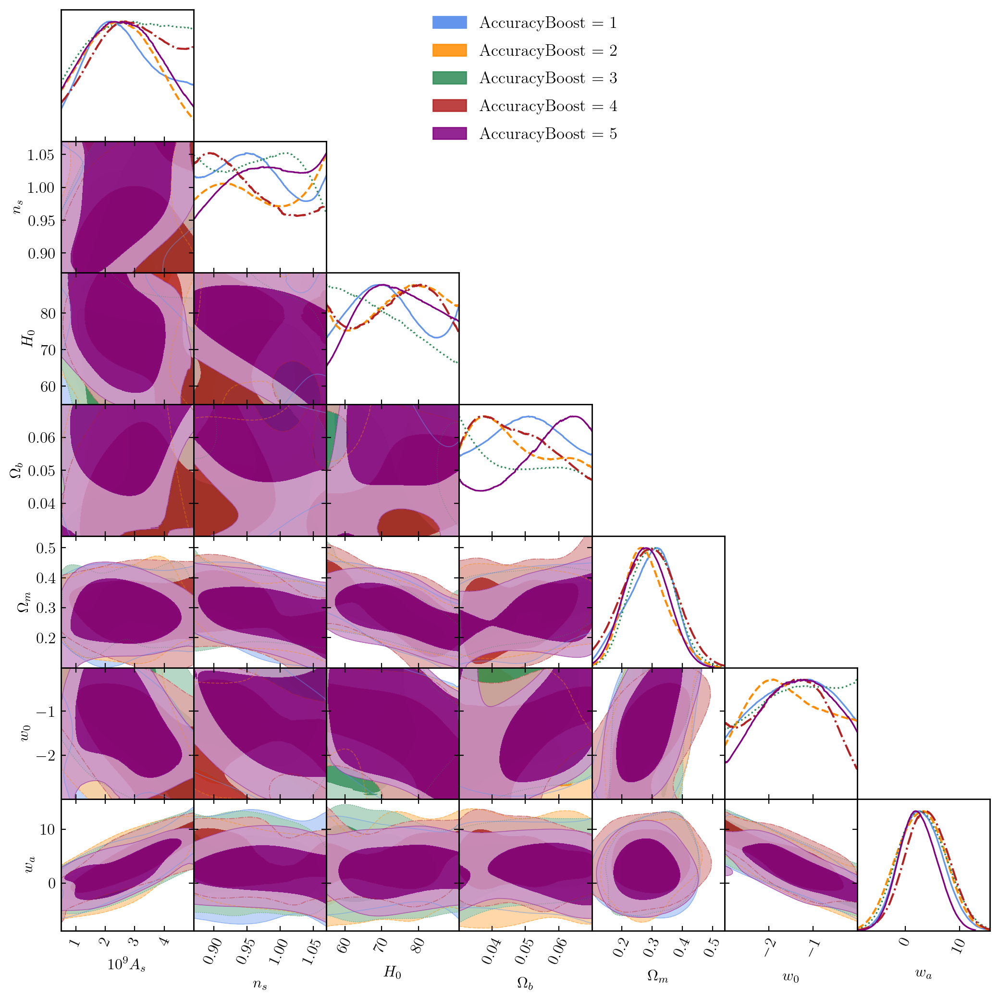

In [39]:
g = nw.plot_Fisher(F=F1,
                   mu=param,
                   select=sel,
                   filled=True,
                   flat_priors=flat_priors,
                   chain_names=['AccuracyBoost = 1', 'AccuracyBoost = 2',
                                'AccuracyBoost = 3', 'AccuracyBoost = 4',
                                'AccuracyBoost = 5'])

<!-- DRAFT: Fable rewrites -->
### Test 2: dependence on the step $h$

Fisher matrices with $h$ from 0.02 to 0.09 at `AccuracyBoost` = 3. Too small a
step lets numerical noise dominate the differences; too large a step picks up
the curvature of the data vector. A plateau of the FoMs over a range of $h$
marks reliable derivatives. The $h=0.03$ matrix is the `AccuracyBoost` = 3
matrix of Test 1 and is reused, not recomputed. The figure shows each FoM
divided by its value at $h=0.03$.

In [40]:
# One Fisher matrix per step h = 0.02, ..., 0.09 at AccuracyBoost = 3. The
# h = 0.03 entry is the AccuracyBoost = 3 matrix of Test 1 (F1[2]): the
# same derivatives, so it is reused instead of recomputed.
hs2 = [0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09]
F2 = []
FOM2_w = []
FOM2_AsOm = []
for x in hs2:
    t0 = time.perf_counter()
    if x == 0.03:
        F = F1[2]
    else:
        F = nw.get_Fisher(CV=param, h=x, AccuracyBoost=3.0)
    F2.append(F)
    FOM2_w.append(cnu.get_FoM(iw0, iwa, F))
    FOM2_AsOm.append(cnu.get_FoM(iAs, iOm, F))
    print(f"h = {x:g}: FoM(w0, wa) = {FOM2_w[-1]:.4g}, "
          f"FoM(10^9 A_s, Omega_m) = {FOM2_AsOm[-1]:.4g} "
          f"({time.perf_counter() - t0:.0f} s)", flush=True)

h = 0.02: FoM(w0, wa) = 0.03131, FoM(10^9 A_s, Omega_m) = 0.3981 (377 s)


h = 0.03: FoM(w0, wa) = 0.03131, FoM(10^9 A_s, Omega_m) = 0.3981 (0 s)


h = 0.04: FoM(w0, wa) = 0.03131, FoM(10^9 A_s, Omega_m) = 0.3974 (375 s)


h = 0.05: FoM(w0, wa) = 0.03131, FoM(10^9 A_s, Omega_m) = 0.3975 (377 s)


h = 0.06: FoM(w0, wa) = 0.03131, FoM(10^9 A_s, Omega_m) = 0.3976 (376 s)


h = 0.07: FoM(w0, wa) = 0.03131, FoM(10^9 A_s, Omega_m) = 0.3978 (378 s)


h = 0.08: FoM(w0, wa) = 0.03131, FoM(10^9 A_s, Omega_m) = 0.3979 (380 s)


h = 0.09: FoM(w0, wa) = 0.03131, FoM(10^9 A_s, Omega_m) = 0.398 (377 s)


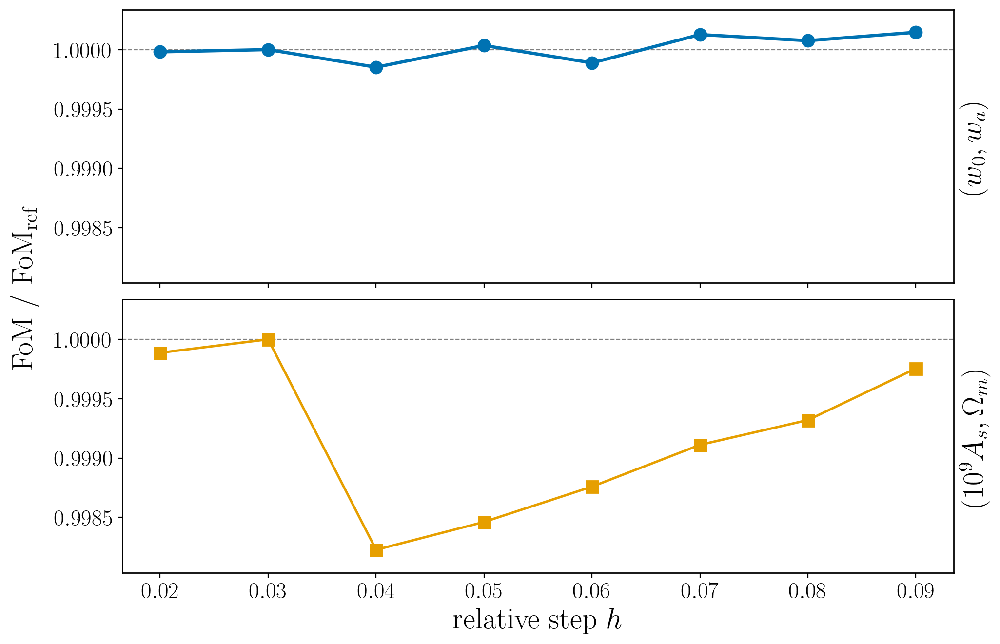

In [41]:
# reference: h = 0.03, the step of Test 1 (index 1 of hs2)
plot_fom_ratio(x=hs2, fom_w=FOM2_w, fom_AsOm=FOM2_AsOm,
               reference=1, xlabel=r"relative step $h$")

Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in


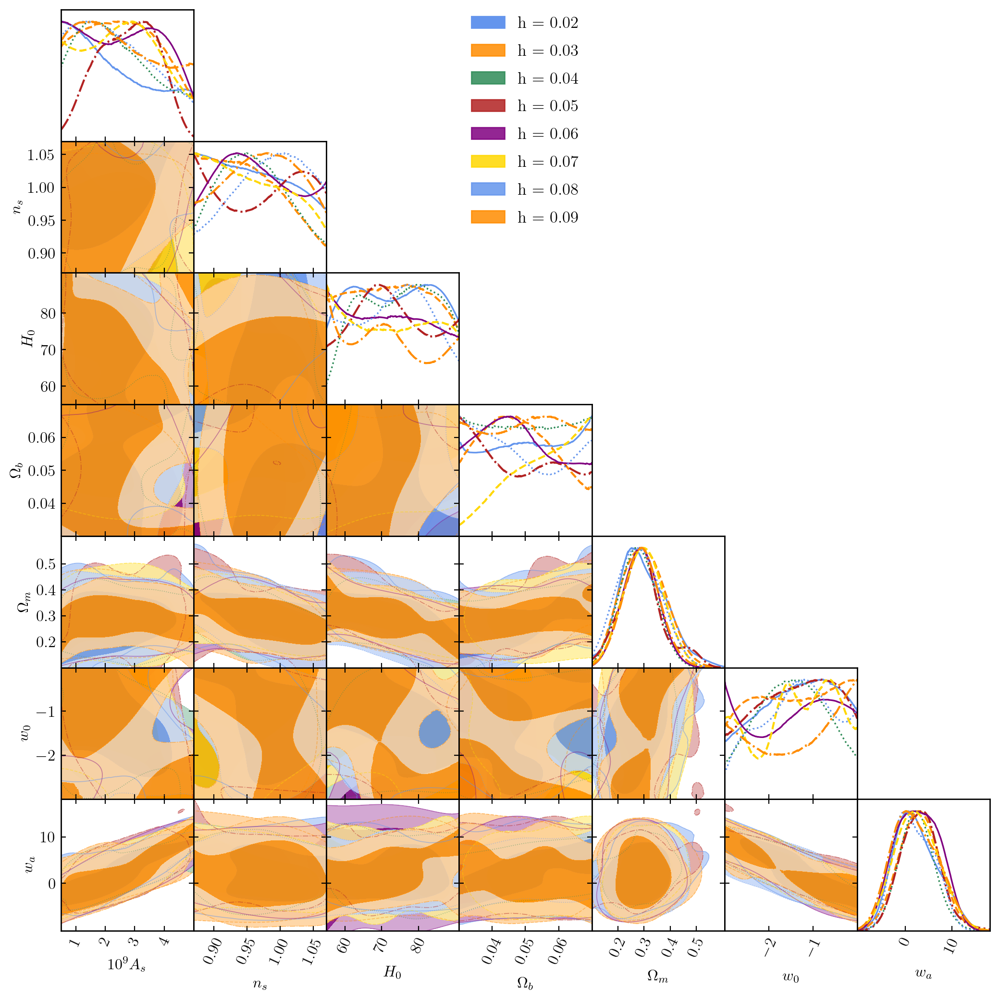

In [42]:
g = nw.plot_Fisher(F=F2,
                   mu=param,
                   select=sel,
                   filled=True,
                   flat_priors=flat_priors,
                   chain_names=['h = 0.02', 'h = 0.03', 'h = 0.04', 'h = 0.05',
                                'h = 0.06', 'h = 0.07', 'h = 0.08', 'h = 0.09'])

<!-- DRAFT: Fable rewrites -->
### Five-point stencil versus derivkit

`nw.get_Fisher2` builds the derivatives with the derivkit package, which fits
polynomials through adaptively chosen samples of the data vector (at least
seven per parameter), so that numerical noise averages out instead of entering
the derivative at full strength. The figure overlays the five-point forecast
($h=0.06$, `AccuracyBoost` = 3, the matrix of Test 2) and the derivkit forecast
(`AccuracyBoost` = 2.5).

Facts for the final text (a scratch check at `AccuracyBoost` = 1, five-point
step $h=0.03$, not part of this notebook): every derivkit derivative column
agrees with the five-point column to better than 4% in whitened norm
$|d_\mathrm{dk}-d_\mathrm{5pt}|_C/|d_\mathrm{5pt}|_C$, except $w_a$, whose fiducial is 0
(10%). Replacing only the $w_a$ column of the five-point matrix by derivkit's
moves FoM$(w_0,w_a)$ from 0.032 to 0.95; every other single-column swap moves
it by less than 1%. The five-point FoM changes by 1% between $h=0.02$ and
$0.06$. Cosmic shear alone leaves the $(w_0,w_a)$ direction nearly degenerate,
so a 10% change of one column changes the FoM thirtyfold.

In [43]:
# the stencil matrix: h = 0.06 at AccuracyBoost = 3, from Test 2
F_stencil = F2[hs2.index(0.06)]
t0 = time.perf_counter()
# importing derivkit (inside nw.get_Fisher2, at its first call) runs its
# own plot style, which replaces matplotlib's global rcParams (no LaTeX,
# gray text, inward ticks); rc_context saves the rcParams on entry and
# restores them on exit, so the later figures keep the notebook's style
with matplotlib.rc_context():
    F_dkit = nw.get_Fisher2(CV=param, AccuracyBoost=2.5)
print(f"derivkit Fisher matrix in {time.perf_counter() - t0:.0f} s")
for (name, F) in (("stencil ", F_stencil), ("derivkit", F_dkit)):
    print(f"{name}: FoM(w0, wa) = {cnu.get_FoM(iw0, iwa, F):.4g}, "
          f"FoM(10^9 A_s, Omega_m) = {cnu.get_FoM(iAs, iOm, F):.4g}")

derivkit Fisher matrix in 799 s
stencil : FoM(w0, wa) = 0.03131, FoM(10^9 A_s, Omega_m) = 0.3976
derivkit: FoM(w0, wa) = 0.1412, FoM(10^9 A_s, Omega_m) = 0.8474


Removed no burn in
Removed no burn in


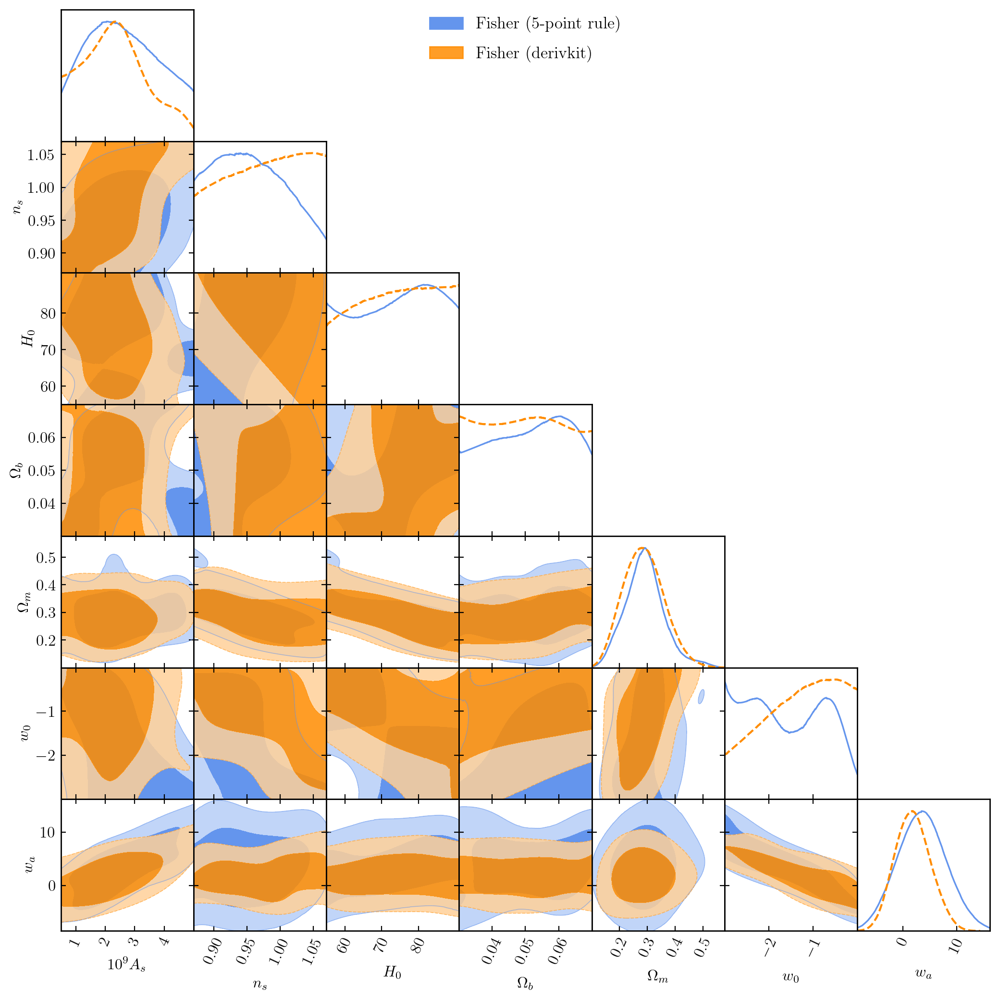

In [44]:
g = nw.plot_Fisher(F=F_stencil,
                   F2=F_dkit,
                   mu=param,
                   select=sel,
                   filled=True,
                   flat_priors=flat_priors,
                   chain_names=['Fisher (5-point rule)', 'Fisher (derivkit)'])

### How numerical noise moves the dark-energy figure of merit

A computed data vector is the smooth model plus a small numerical
error: the integration grids, the distance grids and CAMB's tolerances
leave a remnant that changes irregularly from one parameter value to
the next. A finite-difference derivative divides that error by the
step, so each derivative column $j$ carries a noise vector $e_j$ beside
the true derivative. In the Fisher matrix $F = D^{\mathsf T}C^{-1}D$
the noise term $e_j^{\mathsf T}C^{-1}e_j$ is a sum of squares, positive
for every realization, so on average the noise only adds to $F_{jj}$:
noise looks like information. Off the diagonal, products of independent
errors average to zero. The average addition
$a_j = \langle e_j^{\mathsf T}C^{-1}e_j\rangle$ therefore acts exactly
like a Gaussian prior of width $a_j^{-1/2}$ on parameter $p_j$ - a
prior the data do not carry. Marginalization passes that fake prior to
the $(w_0, w_a)$ block, and to first order it moves the figure of merit
$\mathrm{FoM} = \det C_w^{-1/2}$ (the inverse area of the pair's error
ellipse, with $C_w = (F^{-1})_{ww}$ the pair's marginalized covariance)
by

$$\delta\ln\mathrm{FoM}(w_0, w_a) \simeq \frac{1}{2}\sum_j R_j^2\,a_j\,\sigma_j^2,$$

one term per sampled parameter (the Fisher note of the lssty1xdesi
project, `projects/lssty1xdesi/notes/fisher_machinery`, section
"Derivative accuracy"):

- $\sigma_j^2 = (F^{-1})_{jj}$ is the marginalized forecast variance of
  $p_j$, so $a_j\sigma_j^2$ compares the fake prior with the
  information the data leave on $p_j$ after marginalization;
- $R_j^2 = (F^{-1})_{j,w}\,C_w^{-1}\,(F^{-1})_{w,j}/\sigma_j^2$, with
  $w = (w_0, w_a)$, is the squared multiple correlation of $p_j$ with
  the pair: the share of $p_j$'s forecast variance that a linear fit to
  $(w_0, w_a)$ explains. It is 1 for $w_0$ and $w_a$ themselves and 0
  for a parameter uncorrelated with the pair, so a column's noise
  reaches the figure of merit only through its correlation with the
  pair.

The noise is measured from the five stencil points
$p_j + k\,\varepsilon_j$, $k = -2, \dots, 2$, of the five-point
derivative (`cnu.get_stencil_noise`, five evaluations per column). The
fourth difference
$\Delta_4 m = m(-2) - 4\,m(-1) + 6\,m(0) - 4\,m(1) + m(2)$ removes the
smooth part of the model - every derivative below the fourth cancels,
leaving $O(\varepsilon^4)$ - and keeps the point-to-point jitter.
Whitening it with the data covariance (whitening transforms a vector so
its errors become unit and uncorrelated; its squared length is then a
$\chi^2$) gives the noise of one evaluation,
$\hat\sigma_j = \sqrt{\Delta_4 m^{\mathsf T}C^{-1}\Delta_4 m/70}$, and
the spurious prior $a_j = (130/144)\,(\hat\sigma_j/\varepsilon_j)^2$.
The two constants count squared stencil weights:
$70 = 1 + 16 + 36 + 16 + 1$ from the fourth difference and
$130/144 = (1 + 64 + 64 + 1)/12^2$ from the derivative weights
$(-1, 8, -8, 1)/12$. The step $\varepsilon_j$ is $h\,|p_j|$, or $h$
where the fiducial is zero ($|p_j| \le 10^{-12}$) - the rule of
`cnu.get_ddv`.

The estimate is cheap because $F$, $R_j$ and $\sigma_j$ come once, from
the base matrix of this section. Column $j$ contributes
$(130/288)\,\hat\sigma_j^2\,W_j$ with the dimensionless lever
$W_j = R_j^2\,(\sigma_j/\varepsilon_j)^2$, so the lever ranks the
columns before any noise is measured: the rows below measure the
seven columns that carry 99% of the lever sum
($w_a$, $w_0$, the photo-z shift of source bin 2, $10^9A_s$, $A_1$, $\eta_1$ and $A_2$) and keep $a_j = 0$ for the rest.

The table has one row per `AccuracyBoost` (the range of the `AccuracyBoost` test above), the
highest as the reference. Its columns: the first-order
$\delta\ln\mathrm{FoM}$; the predicted FoM ratio against the reference -
the exact diagonal form $\mathrm{FoM}(F + \mathrm{diag}\,a)/\mathrm{FoM}(F)$ of
the row divided by the reference row's own ratio, since the reference
is not noise free (`cnu.predict_fom_noise`); the measured columns; the
number of data-vector evaluations; the time. A setting has settled when
$\sum_j R_j^2 a_j \sigma_j^2$ ($= 2\,\delta\ln\mathrm{FoM}$) is below
about $10^{-2}$, which keeps the figure of merit within about half a
percent; here every row is far below it: $\sum_j R_j^2 a_j \sigma_j^2$ is $7.7\times10^{-4}$ at `AccuracyBoost` = 1 and $5.2\times10^{-5}$ at 5, so the point-to-point jitter has settled already at the default setting.

The estimate sees one error family only. An error that varies smoothly
across the five stencil points - a resolution offset that bends gently
with the parameter - cancels in the fourth difference exactly as the
smooth model does, yet can still move the derivative. On lsst_y1's
cosmic-shear Fisher matrix the full FoM at `AccuracyBoost` = 1 sat
0.23% from the reference while the jitter prediction was about
$3\times10^{-5}$: that 0.23% is a smooth change of the data vector with
the accuracy settings, invisible to the fourth difference.
The last block prints the full-Fisher
FoM($w_0$, $w_a$) ratios of the scan above next to the predicted
ratios for the same reading here. The prediction answers where the
point-to-point jitter stops mattering; the direct comparison of full
Fisher matrices is what tests the smooth family.

In [45]:
# eps_j = the step of column j at the noise step h_noise, in the
# parameter's own units: h |p0_j|, or h itself for a fiducial at 0 (wa),
# the convention of cnu.get_ddv and cnu.get_stencil_noise.
h_noise = 0.03
eps = np.zeros(len(param))
for k in range(len(param)):
    if np.isclose(param[k], 0.0, atol=1e-12):
        eps[k] = h_noise
    else:
        eps[k] = h_noise*abs(param[k])

# R_j^2, sigma_j^2 and the lever W_j = R_j^2 (sigma_j/eps_j)^2 of every
# column, from the base matrix alone: no data vector is evaluated here
weights = cnu.get_fom_noise_weights(F_base, iw0, iwa, eps=eps)
lever = weights["lever"]
# np.argsort sorts ascending; [::-1] reverses it, so order starts with
# the largest lever
order = np.argsort(lever)[::-1]
lever_sum = np.sum(lever)

# the heavy columns: the shortest head of the ranking whose levers carry
# 99% of the lever sum
heavy = []
cumulative = 0.0
for k in order:
    heavy.append(int(k))
    cumulative = cumulative + lever[k]/lever_sum
    if cumulative >= 0.99:
        break

print(f"{'rank':>4s} {'parameter':>10s} {'R_j^2':>8s} {'sigma_j':>10s} "
      f"{'eps_j':>10s} {'lever W_j':>10s} {'cumulative':>10s}")
cumulative = 0.0
for rank, k in enumerate(order):
    cumulative = cumulative + lever[k]/lever_sum
    marker = "*" if int(k) in heavy else " "
    print(f"{rank + 1:4d} {param_names[k]:>10s} {weights['R2'][k]:8.3f} "
          f"{np.sqrt(weights['sigma2'][k]):10.3e} {eps[k]:10.3e} "
          f"{lever[k]:10.3e} {cumulative:10.4f} {marker}")
print(f"\n{len(heavy)} heavy columns (*) carry 99% of the lever sum: "
      + ", ".join(param_names[k] for k in heavy))


rank  parameter    R_j^2    sigma_j      eps_j  lever W_j cumulative
   1         wa    1.000  2.527e+01  3.000e-02  7.094e+05     0.8756 *
   2         w0    1.000  6.786e+00  2.700e-02  6.317e+04     0.9536 *
   3  DES_DZ_S2    0.174  1.387e-02  4.420e-05  1.718e+04     0.9748 *
   4     As_1e9    0.372  6.648e+00  6.300e-02  4.140e+03     0.9799 *
   5   DES_A1_1    0.702  1.343e+00  1.818e-02  3.833e+03     0.9846 *
   6   DES_A1_2    0.200  5.647e+00  4.546e-02  3.080e+03     0.9884 *
   7   DES_A2_1    0.917  3.098e+00  5.382e-02  3.039e+03     0.9922 *
   8     omegam    0.959  4.486e-01  9.000e-03  2.383e+03     0.9951  
   9     omegab    0.029  3.167e-01  1.200e-03  2.034e+03     0.9976  
  10   DES_A2_2    0.521  1.937e+00  4.634e-02  9.101e+02     0.9987  
  11         H0    0.076  1.868e+02  2.020e+00  6.530e+02     0.9996  
  12  DES_BTA_1    0.233  9.023e-01  2.446e-02  3.176e+02     0.9999  
  13  DES_DZ_S3    0.055  1.064e-02  7.111e-04  1.238e+01     1.0000  
  14    

In [46]:
# the AccuracyBoost rows: the range of Test 1, the highest as reference
AB_noise = [1.0, 2.0, 3.0, 4.0, 5.0]

# a_j of every heavy column at every AccuracyBoost row: five data
# vectors per column (the four of the five-point derivative and the
# center), so a row costs 5 x len(heavy) evaluations
noise = {}
seconds_noise = {}
for ab in AB_noise:
    noise[ab] = {}
    t0 = time.perf_counter()
    for k in heavy:
        noise[ab][k] = cnu.get_stencil_noise(nw.get_dv, index=k, h=h_noise,
                                             CV=param, AccuracyBoost=ab,
                                             invcov=invcov)
    seconds_noise[ab] = time.perf_counter() - t0
    print(f"AccuracyBoost = {ab:g}: {5*len(heavy)} evaluations in "
          f"{seconds_noise[ab]:.0f} s", flush=True)


AccuracyBoost = 1: 35 evaluations in 39 s


AccuracyBoost = 2: 35 evaluations in 91 s


AccuracyBoost = 3: 35 evaluations in 165 s


AccuracyBoost = 4: 35 evaluations in 267 s


AccuracyBoost = 5: 35 evaluations in 445 s


In [47]:
# a = the measured a_j in the heavy columns, 0 elsewhere; the
# reference row is the highest AccuracyBoost, whose own ratio divides
# every row's ratio (the reference is not noise free either)
prediction = {}
for ab in AB_noise:
    a = np.zeros(len(param))
    for k in heavy:
        a[k] = noise[ab][k]["a"]
    prediction[ab] = cnu.predict_fom_noise(F_base, iw0, iwa, a)
reference_ratio = prediction[AB_noise[-1]]["ratio"]

print(f"FoM(w0, wa) noise estimate; base F: {base_label}; noise step "
      f"h = {h_noise}; reference row AccuracyBoost = {AB_noise[-1]:g}")
print(f"{'AccuracyBoost':>13s} {'dlnFoM (1st order)':>19s} "
      f"{'FoM ratio / ref':>16s} {'columns':>8s} {'evaluations':>12s} "
      f"{'time [s]':>9s}  largest term")
for ab in AB_noise:
    p = prediction[ab]
    top = int(np.argmax(p["terms"]))
    print(f"{ab:13g} {p['dlnFoM']:19.3e} {p['ratio']/reference_ratio:16.5f} "
          f"{len(heavy):8d} {5*len(heavy):12d} {seconds_noise[ab]:9.0f}  "
          f"{param_names[top]} ({p['terms'][top]:.2e})")
print("measured columns: " + ", ".join(param_names[k] for k in heavy))

# Test 1 computed full Fisher matrices at the same AccuracyBoost values
# and step: their FoM(w0, wa) relative to AccuracyBoost = 5, next to the
# predicted ratio of the same row
print("\nFoM(w0, wa) / reference: predicted (this table) and full Fisher "
      "matrices (Test 1, h = 0.03)")
print(f"{'AccuracyBoost':>13s} {'predicted':>10s} {'full Fisher':>12s}")
for (x, fom) in zip(AB1, FOM1_w):
    predicted = prediction[float(x)]["ratio"]/reference_ratio
    print(f"{x:13g} {predicted:10.5f} {fom/FOM1_w[-1]:12.5f}")

FoM(w0, wa) noise estimate; base F: h = 0.025, AccuracyBoost = 2.5; noise step h = 0.03; reference row AccuracyBoost = 5
AccuracyBoost  dlnFoM (1st order)  FoM ratio / ref  columns  evaluations  time [s]  largest term
            1           3.825e-04          1.00036        7           35        39  wa (6.59e-04)
            2           1.148e-04          1.00009        7           35        91  DES_DZ_S2 (1.50e-04)
            3           3.824e-05          1.00001        7           35       165  wa (7.18e-05)
            4           3.148e-05          1.00001        7           35       267  wa (5.81e-05)
            5           2.593e-05          1.00000        7           35       445  wa (4.90e-05)
measured columns: wa, w0, DES_DZ_S2, As_1e9, DES_A1_1, DES_A1_2, DES_A2_1

FoM(w0, wa) / reference: predicted (this table) and full Fisher matrices (Test 1, h = 0.03)
AccuracyBoost  predicted  full Fisher
            1    1.00036      1.03113
            2    1.00009      0.99505
    

## The UV-fraction scale cut of $w(\theta)$: $\theta_\mathrm{min}$ against $k_\mathrm{max}$

A scale cut removes the data points a model cannot be trusted to
predict. The UV-fraction criterion (arXiv:2603.13031) asks each data
point how much of it comes from small scales: the 3D power spectrum is
multiplied by a step at $k_\mathrm{max}/D(z)$, with $D$ the linear growth
factor normalized to $D(0) = 1$, which splits every clustering
multipole into $C_\ell = C_\ell^\mathrm{IR} + C_\ell^\mathrm{UV}$ - the part
sourced by modes $k \le k_\mathrm{max}/D(z)$ (IR, infrared: large scales)
and the rest (UV, ultraviolet: small scales). The split passes linearly
through the bin-averaged Legendre projection, so
$w = w_\mathrm{IR} + w_\mathrm{UV}$, and an angular bin is kept while its UV
fraction stays below the threshold $\alpha$:

$$\frac{|w_\mathrm{UV}(\theta)|}{|w_\mathrm{UV}(\theta)| + |w_\mathrm{IR}(\theta)|} < \alpha, \qquad \alpha = 0.05$$

($\alpha = 0.01$ is the conservative variant). $k_\mathrm{max}$ is quoted
at $z = 0$ in $h$/Mpc: each lens bin is cut at $k_\mathrm{max}/D(z)$, a
larger wavenumber at higher redshift. The $1/D$ scaling is an adopted
growth-scaled prescription, not a derived law. This criterion is not
the response-function cut of arXiv:2011.06469.

Two structural rules keep the kept set well defined near the zero
crossings of $w(\theta)$, where either part can change sign and the
fraction is fragile. The kept set is a suffix in $\theta$: the scan starts at the
largest angle and stops at the first bin above $\alpha$, so a smaller
angle whose fraction dips back below $\alpha$ stays cut. And the suffix
only shrinks as $k_\mathrm{max}$ decreases. $\theta_\mathrm{min}$ is the
area-weighted center (arcmin) of the smallest kept bin; when no bin
survives, $\theta_\mathrm{min}$ is reported as the upper edge of the
angular range, 250 arcmin, and the all-zero mask row is the
authoritative statement.

The cut is a diagnostic of the evaluated model, not a filter on the
data: an analysis fixes the selected rows and evaluates the full,
unwindowed theory on them, and the window is never applied to measured
correlation functions. Only the clustering autos are cut - the $k$
window exists in the galaxy-clustering engines only, so $\gamma_t$ and
$\xi_\pm$ are outside it. The cut runs on whichever projection the
likelihood selected; here that is this project's default: the exact
non-Limber evaluation (FKEM) below $\ell = 150$ and the Limber
approximation above (Limber collapses the line-of-sight integral so
each multipole reads a single wavenumber per distance; FKEM keeps the
full integral).

The first figure draws $\theta_\mathrm{min}$ against $k_\mathrm{max}$, one
curve per lens bin, on 12 log-spaced $k_\mathrm{max}$ from 0.05 to
1.0 $h$/Mpc. All five lens bins keep no angular bin at $k_\mathrm{max} \le 0.113\,h$/Mpc ($\theta_\mathrm{min}$ = 250 arcmin), and lens bin 5 keeps none up to $0.256\,h$/Mpc. At $k_\mathrm{max} = 0.3\,h$/Mpc, $\theta_\mathrm{min}$ is 89.7 arcmin for lens bin 1 and 71.2 arcmin for lens bin 5.
In comoving units the smallest kept scale is
$R = \theta_\mathrm{min}\,\chi(\bar z)$, with $\chi(\bar z)$ the comoving
distance to the lens bin's mean redshift: at
$k_\mathrm{max} = 0.3\,h$/Mpc, $R \approx$ $19.8\,h^{-1}\,\mathrm{Mpc}$ for the lowest and
$41.5\,h^{-1}\,\mathrm{Mpc}$ for the highest lens bin. The second figure shows $w$,
$w_\mathrm{IR}$ and $w_\mathrm{UV}$ for lens bin 3 at
$k_\mathrm{max} = 0.3\,h$/Mpc, with the cut region
$\theta < \theta_\mathrm{min}$ shaded: the UV part grows toward small
angles until the fraction crosses $\alpha$.

How much does the projection matter for the cut? Running the same cut
with Limber at every $\ell$ changes $\theta_\mathrm{min}$ only at
8 of the 60 (lens bin, $k_\mathrm{max}$) pairs, six of them at $k_\mathrm{max} \le 0.26\,h$/Mpc and two at 0.336 and $0.58\,h$/Mpc, at the largest angles,
and in both directions: the affected bins sit near a zero crossing of
$w$ with fractions close to $\alpha$, so a small change of the
multipoles moves a bin across the threshold - not a smooth shift of the
cut. The largest change is $-160$ arcmin, for lens bin 5 at $k_\mathrm{max} = 0.256\,h$/Mpc: FKEM keeps no angular bin there, Limber keeps the bins down to 89.7 arcmin. The two agree exactly at every $k_\mathrm{max} \le 0.113$, at 0.442 and at $k_\mathrm{max} \ge 0.762\,h$/Mpc, and lens bin 1 agrees at every $k_\mathrm{max}$. The low-rank (SVD) non-Limber
engine gives the same $\theta_\mathrm{min}$ as FKEM in every bin and at every $k_\mathrm{max}$. The notebook then
restores the default engine, and the next ordinary evaluation
reproduces the data vector bit for bit.

In [48]:
# the clustering state: the 3x2pt probes (no data needed) and one w(theta)
# evaluation at the fiducial point, whose model the cut reads
ini = nw.init_cosmolike(CLprobe="3x2pt")
(theta_w, w_fid) = nw.w_theta()

# 12 k_max values, h/Mpc at z = 0, strictly ascending
kmax = np.geomspace(0.05, 1.0, 12)
t0 = time.perf_counter()
cuts = ci.w_gg_scale_cuts_tomo(kmax=kmax, alpha=0.05)
print(f"12 cuts in {time.perf_counter() - t0:.2f} s")
# theta and kmax arrive as (n, 1) columns; np.ravel makes them 1D
theta = np.ravel(cuts["theta"])
theta_min = cuts["theta_min"]           # (n_lens, n_kmax), arcmin
mask = cuts["mask"]                     # (n_lens, n_theta, n_kmax), 1 = kept

np.set_printoptions(linewidth=150)
print("k_max [h/Mpc]:", " ".join(f"{k:6.3g}" for k in kmax))
for b in range(theta_min.shape[0]):
    print(f"lens bin {b + 1}:   " + " ".join(f"{t:6.3g}" for t in theta_min[b]))

12 cuts in 0.52 s
k_max [h/Mpc]:   0.05 0.0657 0.0862  0.113  0.149  0.195  0.256  0.336  0.442   0.58  0.762      1
lens bin 1:      250    250    250    250    250    142    113   89.7   71.2   44.9   35.7   28.4
lens bin 2:      250    250    250    250    225    225    142   71.2   56.6   44.9   35.7   28.4
lens bin 3:      250    250    250    250    250    179   71.2   56.6   56.6   44.9   17.9   17.9
lens bin 4:      250    250    250    250    225    142   56.6   44.9   44.9   35.7   17.9   14.2
lens bin 5:      250    250    250    250    250    250    250   35.7   28.4   22.5   22.5   17.9


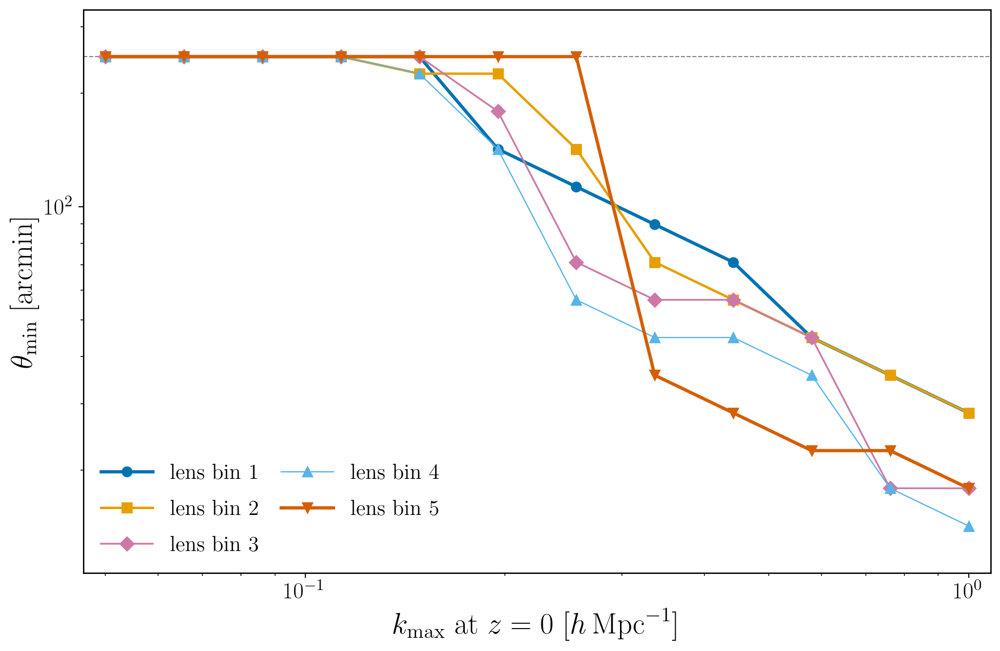

In [49]:
# theta_min per lens bin against k_max; the gray dashed line marks 250
# arcmin, the upper edge of the angular range (no bin kept)
cnu.plot_scale_cuts(kmax=kmax,
                    cut=theta_min,
                    ylabel=r"$\theta_{\rm min}$ [arcmin]",
                    binlabels=[f"lens bin {b + 1}" for b in range(theta_min.shape[0])],
                    xscale="log",
                    yscale="log",
                    yref=[ini.float("theta_max_arcmin")],
                    figsize=(12, 7.5),
                    yaxislabelsize=22,
                    xaxislabelsize=22,
                    yaxisticklabelsize=17,
                    xaxisticklabelsize=17,
                    legendfontsize=16,
                    markersize=7)

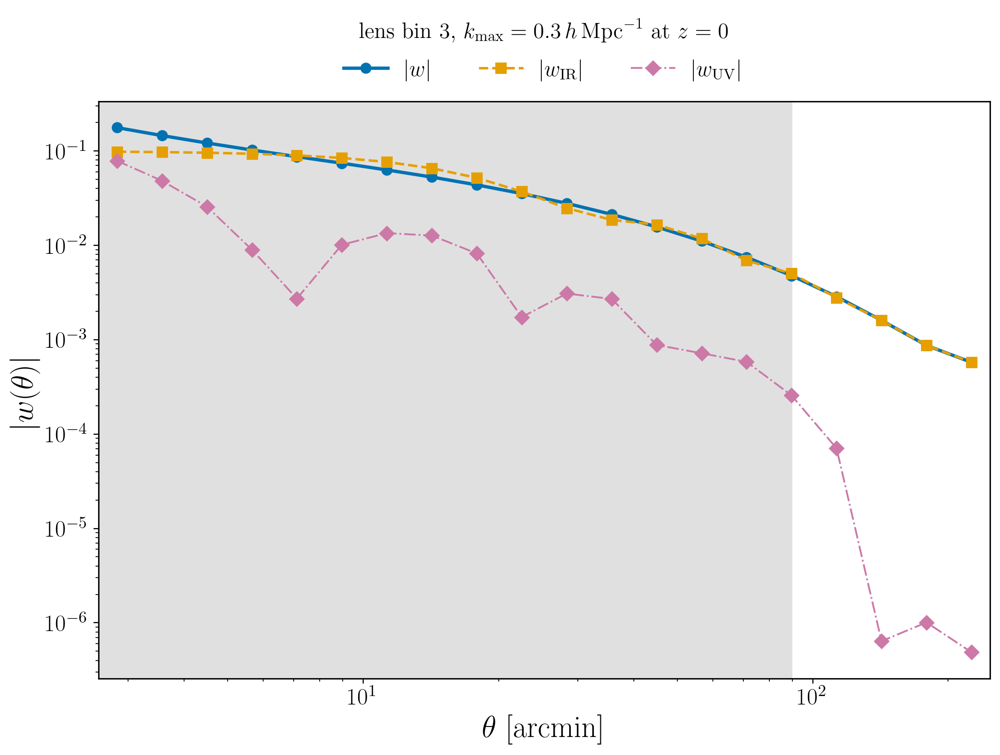

theta_min at k_max = 0.3 h/Mpc (the figure's grid with 0.3 added), lens bins 1-5 [arcmin]: 89.7 113 89.7 71.2 71.2


In [50]:
# (n_lens, n_theta) arrays: the full w (kmax <= 0 switches the window
# off), its IR part (keep_ir = 1) and its UV part (keep_ir = 0)
kmax_panel = 0.3
w_full = ci.w_gg_kwindow_tomo(kmax=-1.0, keep_ir=1)
w_ir = ci.w_gg_kwindow_tomo(kmax=kmax_panel, keep_ir=1)
w_uv = ci.w_gg_kwindow_tomo(kmax=kmax_panel, keep_ir=0)
n_lens = w_full.shape[0]
# theta_min of every lens bin at k_max = 0.3, from the figure's grid with
# 0.3 added: the monotone rule (the kept suffix only shrinks as k_max
# decreases) then covers this value as it covers the figure's, and a cut
# at 0.3 can keep no smaller angle than the cut at the next grid value
kmax_with_panel = np.sort(np.append(kmax, kmax_panel))
cut_panel = ci.w_gg_scale_cuts_tomo(kmax=kmax_with_panel, alpha=0.05)
panel_column = int(np.argmin(np.abs(kmax_with_panel - kmax_panel)))
theta_min_panel = cut_panel["theta_min"][:, panel_column]

# the mid lens bin of five: bin 3, index 2
mid = 2
fig, ax = plt.subplots(figsize=(11.5, 7.5))
# the cut region theta < theta_min, behind the curves; its left edge lies
# outside the x range, so the band starts at the frame
ax.axvspan(theta[0]/1.2, theta_min_panel[mid], color="0.88", zorder=0)
# one entry per curve: (values, label, color, width, line style, marker);
# colorblind-safe colors, and each curve also differs in width, line style
# and marker
curves = [(w_full, r"$|w|$", "#0072B2", 2.4, "solid", "o"),
          (w_ir, r"$|w_{\rm IR}|$", "#E69F00", 1.8, "dashed", "s"),
          (w_uv, r"$|w_{\rm UV}|$", "#CC79A7", 1.3, "dashdot", "D")]
for (w_rows, label, color, width, style, marker) in curves:
    ax.plot(theta, np.abs(w_rows[mid]), color=color, linewidth=width,
            linestyle=style, marker=marker, markersize=7, label=label)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(theta[0]/1.1, theta[-1]*1.1)
ax.set_xlabel(r"$\theta$ [arcmin]", fontsize=22)
ax.set_ylabel(r"$|w(\theta)|$", fontsize=22)
ax.tick_params(labelsize=17)
# the legend sits above the axes, where it cannot touch a curve
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncols=3,
          frameon=False, fontsize=16,
          title=r"lens bin 3, $k_{\rm max} = 0.3\,h\,{\rm Mpc}^{-1}$ at $z = 0$",
          title_fontsize=16)
plt.show()
print("theta_min at k_max = 0.3 h/Mpc (the figure's grid with 0.3 added), "
      "lens bins 1-5 [arcmin]:", " ".join(f"{t:.3g}" for t in theta_min_panel))

In [51]:
# mean redshift of each lens bin from the n(z) table: column 0 holds the
# left bin edges (photoz_zmid_convention = 0), so the bin centers are
# z_low + dz/2; the photo-z shifts (|Delta z| < 0.015) are left out
nz = np.loadtxt(ini.relativeFileName('nz_lens_file'))
z_low = nz[:, 0]
z_center = z_low + 0.5*(z_low[1] - z_low[0])
z_mean = []
for b in range(n_lens):
    z_mean.append(np.sum(z_center*nz[:, b + 1])/np.sum(nz[:, b + 1]))

# chi(z) in Mpc/h at the fiducial cosmology, from the same CAMB call the
# wrappers make
(log10k_2D, z_2D, lnPL, lnPNL, G_growth, z_growth, z_1D, chi_1D, omegan2,
 lnPL_cb) = cnu.get_camb_cosmology(omegam=nw.omegam, omegab=nw.omegab,
                                   H0=nw.H0, ns=nw.ns, As_1e9=nw.As_1e9,
                                   w=nw.w, w0pwa=nw.w0pwa, mnu=nw.mnu)
arcmin = np.pi/(180.0*60.0)
for b in (0, n_lens - 1):
    chi_b = np.interp(z_mean[b], z_1D, chi_1D)
    print(f"lens bin {b + 1}: z_mean = {z_mean[b]:.3f}, chi = {chi_b:.0f} Mpc/h, "
          f"theta_min = {theta_min_panel[b]:.3g} arcmin -> "
          f"R = {theta_min_panel[b]*arcmin*chi_b:.1f} Mpc/h")

lens bin 1: z_mean = 0.273, chi = 758 Mpc/h, theta_min = 89.7 arcmin -> R = 19.8 Mpc/h
lens bin 5: z_mean = 0.848, chi = 2002 Mpc/h, theta_min = 71.2 arcmin -> R = 41.5 Mpc/h


In [52]:
# Limber at every multipole
ci.init_adopt_limber_gg(adopt_limber_gg=1)
cuts_limber = ci.w_gg_scale_cuts_tomo(kmax=kmax, alpha=0.05)
ci.init_adopt_limber_gg(adopt_limber_gg=0)
# the low-rank (SVD) non-Limber engine: 5 ranks, multipole cap 150
ci.init_lowrank_nonlimber_gg(flag=1, nrank=5, lmax=150)
cuts_svd = ci.w_gg_scale_cuts_tomo(kmax=kmax, alpha=0.05)
ci.init_lowrank_nonlimber_gg(flag=0, nrank=5, lmax=150)

difference = cuts_limber["theta_min"] - theta_min
print("theta_min [arcmin]: FKEM | Limber - FKEM ('.' = equal)")
print("k_max [h/Mpc]: " + " ".join(f"{k:6.3g}" for k in kmax))
for b in range(theta_min.shape[0]):
    fkem_row = " ".join(f"{t:6.3g}" for t in theta_min[b])
    diff_row = []
    for d in difference[b]:
        if d == 0.0:
            diff_row.append(f"{'.':>6s}")
        else:
            diff_row.append(f"{d:+6.3g}")
    print(f"lens bin {b + 1}: {fkem_row} | " + " ".join(diff_row))
print(f"Limber differs from FKEM in {int(np.sum(difference != 0))} of "
      f"{difference.size} entries; at k_max >= 0.3 h/Mpc in "
      f"{int(np.sum(difference[:, kmax >= 0.3] != 0))} of "
      f"{difference[:, kmax >= 0.3].size}")
if np.array_equal(cuts_svd["theta_min"], theta_min):
    print("SVD (low-rank) theta_min equals FKEM in every lens bin and k_max")
else:
    print("SVD - FKEM theta_min:\n", cuts_svd["theta_min"] - theta_min)

# back to the project default (FKEM) through the full init sequence, and
# a check that the clustering model is the default one again
ini = nw.init_cosmolike(CLprobe="3x2pt")
(theta_w2, w_fid2) = nw.w_theta()
print("w(theta) after the restore equals the first evaluation bit for bit:",
      np.array_equal(w_fid, w_fid2))
print(f"largest |difference| / max|w|: "
      f"{np.max(np.abs(w_fid2 - w_fid))/np.max(np.abs(w_fid)):.1e}")

theta_min [arcmin]: FKEM | Limber - FKEM ('.' = equal)
k_max [h/Mpc]:   0.05 0.0657 0.0862  0.113  0.149  0.195  0.256  0.336  0.442   0.58  0.762      1
lens bin 1:    250    250    250    250    250    142    113   89.7   71.2   44.9   35.7   28.4 |      .      .      .      .      .      .      .      .      .      .      .      .
lens bin 2:    250    250    250    250    225    225    142   71.2   56.6   44.9   35.7   28.4 |      .      .      .      .  +24.7      .      .      .      .      .      .      .
lens bin 3:    250    250    250    250    250    179   71.2   56.6   56.6   44.9   17.9   17.9 |      .      .      .      .      .  +46.3      .      .      .      .      .      .
lens bin 4:    250    250    250    250    225    142   56.6   44.9   44.9   35.7   17.9   14.2 |      .      .      .      .  +24.7      .      .  +11.6      .      .      .      .
lens bin 5:    250    250    250    250    250    250    250   35.7   28.4   22.5   22.5   17.9 |      .      .      .

w(theta) after the restore equals the first evaluation bit for bit: True
largest |difference| / max|w|: 0.0e+00
